### Task 2: Import Essential Python Libraries

Here is a brief explanation of the libraries we are importing:

* **`numpy` (as `np`)**: Used for performing fast mathematical operations on arrays and matrices.
* **`pandas` (as `pd`)**: Used for data manipulation and analysis, especially with structures like DataFrames.
* **`matplotlib.pyplot` (as `plt`)**: A basic plotting library for creating static visualizations.
* **`seaborn` (as `sns`)**: Built on top of matplotlib, it provides a high-level interface for drawing attractive statistical graphics.
* **`os`**: Provides functions for interacting with the operating system (e.g., handling file paths).
* **`ast` (Abstract Syntax Trees)**: Useful for safely evaluating strings containing Python literal structures (like lists or dictionaries inside strings).
* **`TfidfVectorizer` (from `sklearn.feature_extraction.text`)**: Converts raw text documents into a matrix of TF-IDF features, which is essential for text-based recommendation.
* **`cosine_similarity` (from `sklearn.metrics.pairwise`)**: Measures the similarity between two non-zero vectors, commonly used in collaborative or content-based filtering.
* **`train_test_split` (from `sklearn.model_selection`)**: Splits datasets into random train and test subsets for model evaluation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import ast

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

print("All essential libraries imported successfully!")

All essential libraries imported successfully!


### Task 3.3: Extracting the TMDB Dataset

We will extract the contents of the uploaded zip file `archive (2).zip` into a target directory called `tmdb_dataset` using Python's built-in `zipfile` module. Afterward, we will verify that both required CSV files (`tmdb_5000_movies.csv` and `tmdb_5000_credits.csv`) are successfully extracted.

In [ ]:
import zipfile
import os

zip_path = '/content/archive (2).zip'
extract_dir = '/content/tmdb_dataset'

# Extract the ZIP file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# List all extracted files
extracted_files = os.listdir(extract_dir)
print("Extracted files:", extracted_files)

# Verify existence of required files
required_files = ['tmdb_5000_movies.csv', 'tmdb_5000_credits.csv']
files_exist = all(file in extracted_files for file in required_files)

if files_exist:
    print("Success: Both tmdb_5000_movies.csv and tmdb_5000_credits.csv exist!")
else:
    print("Warning: Some expected files are missing.")

Extracted files: ['tmdb_5000_credits.csv', 'tmdb_5000_movies.csv']
Success: Both tmdb_5000_movies.csv and tmdb_5000_credits.csv exist!


### Task 3.4: Load TMDB Dataset into Pandas DataFrames

We will use `pd.read_csv()` to load the movies and credits datasets into individual DataFrames, and explore their dimensions, schemas, and initial structures.

In [ ]:
import pandas as pd

# 1. Load the CSV files
movies = pd.read_csv('/content/tmdb_dataset/tmdb_5000_movies.csv')
credits = pd.read_csv('/content/tmdb_dataset/tmdb_5000_credits.csv')

# 2. Display the shapes
print(f"Movies Dataset Shape: {movies.shape}")
print(f"Credits Dataset Shape: {credits.shape}\n")

# 3. Print the column names
print("Movies Columns:", list(movies.columns))
print("Credits Columns:", list(credits.columns))
print("\n" + "="*50 + "\n")

# 4. Display basic dataset info
print("--- Movies Dataset Info ---")
movies.info()
print("\n--- Credits Dataset Info ---")
credits.info()
print("\n" + "="*50 + "\n")

# 5. Display the first 5 rows
print("--- First 5 Rows of Movies ---")
display(movies.head())

print("\n--- First 5 Rows of Credits ---")
display(credits.head())

Movies Dataset Shape: (4803, 20)
Credits Dataset Shape: (4803, 4)

Movies Columns: ['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']
Credits Columns: ['movie_id', 'title', 'cast', 'crew']


--- Movies Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124



--- First 5 Rows of Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


### Task 3.5: Statistical Exploration of TMDB Dataset

We will explore the numerical features of the movies dataset to understand distributions and key metrics such as budget, revenue, ratings, and runtime.

In [ ]:
# 1. Descriptive statistics of numerical columns
print("--- Descriptive Statistics of Numerical Columns ---")
display(movies.describe())
print("\n" + "="*50 + "\n")

# 2. Budget metrics
avg_budget = movies['budget'].mean()
min_budget = movies['budget'].min()
max_budget = movies['budget'].max()
print(f"Movie Budget Metrics:")
print(f"  - Average Budget: ${avg_budget:,.2f}")
print(f"  - Minimum Budget: ${min_budget:,.2f}")
print(f"  - Maximum Budget: ${max_budget:,.2f}\n")

# 3. Revenue metrics
avg_revenue = movies['revenue'].mean()
min_revenue = movies['revenue'].min()
max_revenue = movies['revenue'].max()
print(f"Movie Revenue Metrics:")
print(f"  - Average Revenue: ${avg_revenue:,.2f}")
print(f"  - Minimum Revenue: ${min_revenue:,.2f}")
print(f"  - Maximum Revenue: ${max_revenue:,.2f}\n")

# 4. Rating metrics
avg_vote = movies['vote_average'].mean()
print(f"Movie Rating Metrics:")
print(f"  - Average Vote: {avg_vote:.2f}/10\n")

# 5. Runtime metrics
avg_runtime = movies['runtime'].mean()
min_runtime = movies['runtime'].min()
max_runtime = movies['runtime'].max()
print(f"Movie Runtime Metrics:")
print(f"  - Average Runtime: {avg_runtime:.2f} minutes")
print(f"  - Minimum Runtime: {min_runtime:.2f} minutes")
print(f"  - Maximum Runtime: {max_runtime:.2f} minutes\n")

# 6. Unique movie IDs count
unique_ids = movies['id'].nunique()
print(f"Unique Movie IDs: {unique_ids}")

--- Descriptive Statistics of Numerical Columns ---


,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,4.803000e+03,4803.000000,4803.000000,4.803000e+03,4801.000000,4803.000000,4803.000000
mean,2.904504e+07,57165.484281,21.492301,8.226064e+07,106.875859,6.092172,690.217989
std,4.072239e+07,88694.614033,31.816650,1.628571e+08,22.611935,1.194612,1234.585891
min,0.000000e+00,5.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,7.900000e+05,9014.500000,4.668070,0.000000e+00,94.000000,5.600000,54.000000
50%,1.500000e+07,14629.000000,12.921594,1.917000e+07,103.000000,6.200000,235.000000
75%,4.000000e+07,58610.500000,28.313505,9.291719e+07,118.000000,6.800000,737.000000
max,3.800000e+08,459488.000000,875.581305,2.787965e+09,338.000000,10.000000,13752.000000




Movie Budget Metrics:
  - Average Budget: $29,045,039.88
  - Minimum Budget: $0.00
  - Maximum Budget: $380,000,000.00

Movie Revenue Metrics:
  - Average Revenue: $82,260,638.65
  - Minimum Revenue: $0.00
  - Maximum Revenue: $2,787,965,087.00

Movie Rating Metrics:
  - Average Vote: 6.09/10

Movie Runtime Metrics:
  - Average Runtime: 106.88 minutes
  - Minimum Runtime: 0.00 minutes
  - Maximum Runtime: 338.00 minutes

Unique Movie IDs: 4803


### Task 3.6: Missing Values and Duplicate Analysis

We will now inspect both datasets for data quality issues, specifically focusing on missing values (nulls) and duplicates in rows or primary keys (`id` and `movie_id`).

In [ ]:
# 1. Missing values analysis for movies
print("=== MOVIES DATASET: MISSING VALUES ===")
movies_missing = movies.isnull().sum()
movies_missing_pct = (movies.isnull().sum() / len(movies)) * 100
movies_missing_df = pd.DataFrame({
    'Missing Count': movies_missing,
    'Percentage (%)': movies_missing_pct
})
display(movies_missing_df)
print("\n" + "="*50 + "\n")

# 2. Missing values analysis for credits
print("=== CREDITS DATASET: MISSING VALUES ===")
credits_missing = credits.isnull().sum()
credits_missing_pct = (credits.isnull().sum() / len(credits)) * 100
credits_missing_df = pd.DataFrame({
    'Missing Count': credits_missing,
    'Percentage (%)': credits_missing_pct
})
display(credits_missing_df)
print("\n" + "="*50 + "\n")

# 3. Duplicate rows analysis
movies_dup_rows = movies.duplicated().sum()
credits_dup_rows = credits.duplicated().sum()
print("=== DUPLICATE ROWS SUMMARY ===")
print(f"Duplicate rows in movies: {movies_dup_rows}")
print(f"Duplicate rows in credits: {credits_dup_rows}\n")

# 4. Duplicate ID analysis
movies_dup_ids = movies['id'].duplicated().sum()
credits_dup_ids = credits['movie_id'].duplicated().sum()
print("=== DUPLICATE KEY ANALYSIS ===")
print(f"Duplicate 'id' values in movies: {movies_dup_ids}")
print(f"Duplicate 'movie_id' values in credits: {credits_dup_ids}")

=== MOVIES DATASET: MISSING VALUES ===


,Missing Count,Percentage (%)
budget,0,0.000000
genres,0,0.000000
homepage,3091,64.355611
id,0,0.000000
keywords,0,0.000000
original_language,0,0.000000
original_title,0,0.000000
overview,3,0.062461
popularity,0,0.000000
production_companies,0,0.000000




=== CREDITS DATASET: MISSING VALUES ===


,Missing Count,Percentage (%)
movie_id,0,0.0
title,0,0.0
cast,0,0.0
crew,0,0.0




=== DUPLICATE ROWS SUMMARY ===
Duplicate rows in movies: 0
Duplicate rows in credits: 0

=== DUPLICATE KEY ANALYSIS ===
Duplicate 'id' values in movies: 0
Duplicate 'movie_id' values in credits: 0


### Task 3.7: Data Integration – Merge Movies and Credits

We will verify that the ID columns across both datasets align perfectly in data type and unique counts, safely merge the two datasets on these IDs (dropping the duplicate `title` from credits first) into a new DataFrame called `merged_movies`, and inspect the resulting dataset.

In [ ]:
# 1. Verify data types of the ID columns
print(f"Data type of movies['id']: {movies['id'].dtype}")
print(f"Data type of credits['movie_id']: {credits['movie_id'].dtype}\n")

# 2. Check unique values count alignment
unique_movies_ids = movies['id'].nunique()
unique_credits_ids = credits['movie_id'].nunique()
print(f"Unique IDs in movies: {unique_movies_ids}")
print(f"Unique IDs in credits: {unique_credits_ids}")
print(f"Do they have the same number of unique values? {unique_movies_ids == unique_credits_ids}\n")

# 3. Drop 'title' from credits to avoid duplicate title columns, then merge
# (We do this on a temporary copy or inline reference to protect original credits DataFrame)
credits_no_title = credits.drop(columns=['title'])

merged_movies = pd.merge(
    movies,
    credits_no_title,
    left_on='id',
    right_on='movie_id',
    how='left'
)

# 4. Display shape and columns
print("=== MERGED DATASET SUMMARY ===")
print(f"Merged DataFrame Shape: {merged_movies.shape}")
print("Columns:", list(merged_movies.columns))
print("\n" + "="*50 + "\n")

# 5. Display first 5 rows of selected columns
selected_cols = ['id', 'title', 'genres', 'keywords', 'cast', 'crew']
print("Preview of selected columns in merged_movies:")
display(merged_movies[selected_cols].head())
print("\n" + "="*50 + "\n")

# 6. Verify that no movie records were lost
original_count = len(movies)
merged_count = len(merged_movies)
print(f"Original movies count: {original_count}")
print(f"Merged movies count: {merged_count}")
print(f"Were records preserved perfectly? {original_count == merged_count}")

Data type of movies['id']: int64
Data type of credits['movie_id']: int64

Unique IDs in movies: 4803
Unique IDs in credits: 4803
Do they have the same number of unique values? True

=== MERGED DATASET SUMMARY ===
Merged DataFrame Shape: (4803, 23)
Columns: ['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'movie_id', 'cast', 'crew']


Preview of selected columns in merged_movies:


,id,title,genres,keywords,cast,crew
0,19995,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...","[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...","[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 818, ""name"": ""based on novel""}, {""id"":...","[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."




Original movies count: 4803
Merged movies count: 4803
Were records preserved perfectly? True


### Task 3.8: Data Cleaning – Remove Irrelevant Columns

In this step, we will:
1. Create a backup copy of the integrated dataset called `merged_movies_raw` to ensure we can restore the raw data if needed.
2. Permanently drop the highly sparse and irrelevant columns: `homepage` and `tagline` from our active DataFrame `merged_movies`.
3. Verify that the columns have been successfully removed by inspecting the shape, list of remaining columns, and checking for their existence.

In [ ]:
# 1. Create a backup copy of the merged DataFrame
merged_movies_raw = merged_movies.copy()

# 2. Remove 'homepage' and 'tagline' columns
merged_movies = merged_movies.drop(columns=['homepage', 'tagline'])

# 3. Display updated shape
print("=== UPDATED DATASET SHAPE ===")
print(f"New Shape: {merged_movies.shape}\n")

# 4. Display all remaining column names
remaining_columns = list(merged_movies.columns)
print("=== REMAINING COLUMNS ===")
print(remaining_columns)
print("\n" + "="*50 + "\n")

# 5. Verify that 'homepage' and 'tagline' no longer exist in merged_movies
homepage_exists = 'homepage' in merged_movies.columns
tagline_exists = 'tagline' in merged_movies.columns
print("=== COLUMNS REMOVAL VERIFICATION ===")
print(f"Does 'homepage' still exist? {homepage_exists}")
print(f"Does 'tagline' still exist? {tagline_exists}")
print(f"Does 'homepage' exist in backup raw copy? {'homepage' in merged_movies_raw.columns}")
print(f"Does 'tagline' exist in backup raw copy? {'tagline' in merged_movies_raw.columns}")
print("\n" + "="*50 + "\n")

# 6. Display the first 5 rows
print("=== FIRST 5 ROWS OF CLEANED DATASET ===")
display(merged_movies.head())

=== UPDATED DATASET SHAPE ===
New Shape: (4803, 21)

=== REMAINING COLUMNS ===
['budget', 'genres', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'title', 'vote_average', 'vote_count', 'movie_id', 'cast', 'crew']


=== COLUMNS REMOVAL VERIFICATION ===
Does 'homepage' still exist? False
Does 'tagline' still exist? False
Does 'homepage' exist in backup raw copy? True
Does 'tagline' exist in backup raw copy? True


=== FIRST 5 ROWS OF CLEANED DATASET ===


,budget,genres,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,...,revenue,runtime,spoken_languages,status,title,vote_average,vote_count,movie_id,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",...,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Avatar,7.2,11800,19995,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",...,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Pirates of the Caribbean: At World's End,6.9,4500,285,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",...,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,Spectre,6.3,4466,206647,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",...,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Dark Knight Rises,7.6,9106,49026,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",...,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,John Carter,6.1,2124,49529,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


### Task 3.9: Data Cleaning – Handling Missing Values in Specific Columns

In this step, we will target the minor missing values in three columns of `merged_movies`:
1. **`overview`**: Fill the 3 missing values with an empty string `''` to prevent text-processing errors.
2. **`runtime`**: Impute the 2 missing values using the dataset's median runtime to keep numerical analysis robust without introducing outliers.
3. **`release_date`**: Convert the column to datetime format using `pd.to_datetime` (retaining the 1 missing value for now as requested).

In [ ]:
# 1. Display missing values before treatment
target_columns = ['overview', 'runtime', 'release_date']
print("=== MISSING VALUES BEFORE TREATMENT ===")
print(merged_movies[target_columns].isnull().sum())
print("\n" + "="*50 + "\n")

# 2. Fill missing values in 'overview' with an empty string ''
merged_movies['overview'] = merged_movies['overview'].fillna('')

# 3. Calculate median of 'runtime' and fill missing runtime values with it
median_runtime = merged_movies['runtime'].median()
merged_movies['runtime'] = merged_movies['runtime'].fillna(median_runtime)

# 4. Convert 'release_date' into datetime format
merged_movies['release_date'] = pd.to_datetime(merged_movies['release_date'], errors='coerce')

# 5. Display missing values in these three columns after treatment
print("=== MISSING VALUES AFTER TREATMENT ===")
print(merged_movies[target_columns].isnull().sum())
print("\n" + "="*50 + "\n")

# 6. Print the median runtime used for imputation
print(f"Median runtime used for imputation: {median_runtime} minutes\n")

# 7. Verify that overview and runtime have zero missing values
overview_nulls = merged_movies['overview'].isnull().sum()
runtime_nulls = merged_movies['runtime'].isnull().sum()
print("=== VERIFICATION ===")
print(f"Are all missing values resolved in 'overview'? {overview_nulls == 0} (Remaining nulls: {overview_nulls})")
print(f"Are all missing values resolved in 'runtime'? {runtime_nulls == 0} (Remaining nulls: {runtime_nulls})")

=== MISSING VALUES BEFORE TREATMENT ===
overview        3
runtime         2
release_date    1
dtype: int64


=== MISSING VALUES AFTER TREATMENT ===
overview        0
runtime         0
release_date    1
dtype: int64


Median runtime used for imputation: 103.0 minutes

=== VERIFICATION ===
Are all missing values resolved in 'overview'? True (Remaining nulls: 0)
Are all missing values resolved in 'runtime'? True (Remaining nulls: 0)


### Task 3.10: Final Missing Values Verification

Now, we will perform a final verification to examine the missing values across all 21 columns of our cleaned `merged_movies` DataFrame to verify the effectiveness of our previous operations.

In [ ]:
# 1. Display missing value counts for all 21 columns
all_missing_counts = merged_movies.isnull().sum()
print("=== MISSING VALUES FOR ALL COLUMNS ===")
print(all_missing_counts)
print("\n" + "="*50 + "\n")

# 2. Display only columns that still contain missing values
columns_with_missing = all_missing_counts[all_missing_counts > 0]
print("=== COLUMNS STILL CONTAINING MISSING VALUES ===")
if not columns_with_missing.empty:
    print(columns_with_missing)
else:
    print("No columns contain missing values!")
print("\n" + "="*50 + "\n")

# 3. Calculate the total number of missing values in the entire DataFrame
total_missing = merged_movies.isnull().sum().sum()
print(f"Total missing values in the entire DataFrame: {total_missing}\n")

# 4. Display the current shape of merged_movies
print(f"Current shape of merged_movies: {merged_movies.shape}\n")

# 5. Verify that overview and runtime contain zero missing values
overview_clean = merged_movies['overview'].isnull().sum() == 0
runtime_clean = merged_movies['runtime'].isnull().sum() == 0
print("=== TARGET COLUMN VERIFICATION ===")
print(f"Is 'overview' clean? {overview_clean}")
print(f"Is 'runtime' clean? {runtime_clean}")

=== MISSING VALUES FOR ALL COLUMNS ===
budget                  0
genres                  0
id                      0
keywords                0
original_language       0
original_title          0
overview                0
popularity              0
production_companies    0
production_countries    0
release_date            1
revenue                 0
runtime                 0
spoken_languages        0
status                  0
title                   0
vote_average            0
vote_count              0
movie_id                0
cast                    0
crew                    0
dtype: int64


=== COLUMNS STILL CONTAINING MISSING VALUES ===
release_date    1
dtype: int64


Total missing values in the entire DataFrame: 1

Current shape of merged_movies: (4803, 21)

=== TARGET COLUMN VERIFICATION ===
Is 'overview' clean? True
Is 'runtime' clean? True


### Task 3.11: Investigate Missing Release Date

Before deciding how to clean the missing `'release_date'`, we need to identify the exact movie record affected and inspect its properties. This allows us to make an informed, contextual decision (e.g., look up the true release date online) rather than blindly applying default imputations.

In [ ]:
# 1. Filter rows where release_date is null
missing_release_date_df = merged_movies[merged_movies['release_date'].isnull()]

# 2. Display movie id, title, original_title, and release_date
columns_to_show = ['id', 'title', 'original_title', 'release_date']
print("=== MOVIE(S) WITH MISSING RELEASE DATE ===")
display(missing_release_date_df[columns_to_show])
print("\n" + "=== STATISTICS ===")

# 3. Display the total number of affected movies
affected_count = len(missing_release_date_df)
print(f"Total number of affected movies: {affected_count}")

# 4. Explanation print statement as requested
print("\n=== IMPORTANCE OF INVESTIGATION BEFORE TREATMENT ===")
print("Identifying the affected record is crucial because:")
print("1. Since only one record is missing, it is highly efficient and accurate to look up and input the exact historical release date manually.")
print("2. Default imputation (like median or forward-fill) might introduce chronological inaccuracies for a specific film, affecting time-series or seasonal recommendations.")
print("3. It prevents unnecessary deletion of a valid movie record if other metadata fields are complete and useful.")

=== MOVIE(S) WITH MISSING RELEASE DATE ===


,id,title,original_title,release_date
4553,380097,America Is Still the Place,America Is Still the Place,NaT



=== STATISTICS ===
Total number of affected movies: 1

=== IMPORTANCE OF INVESTIGATION BEFORE TREATMENT ===
Identifying the affected record is crucial because:
1. Since only one record is missing, it is highly efficient and accurate to look up and input the exact historical release date manually.
2. Default imputation (like median or forward-fill) might introduce chronological inaccuracies for a specific film, affecting time-series or seasonal recommendations.
3. It prevents unnecessary deletion of a valid movie record if other metadata fields are complete and useful.


### Task A: Final Verification

Is task mein hum log humare current dataset (`merged_movies`) ka shape aur missing values check karenge. Hum ye bhi confirm karenge ki movie ID `380097` (America Is Still the Place) humare data mein safe hai aur humare paas pure **4803** records maujood hain.

In [ ]:
# 1. Verify shape of the dataset
print("=== DATASET SHAPE ===")
print(f"Current shape of merged_movies: {merged_movies.shape}")

# 2. Check missing values
print("\n=== MISSING VALUES PER COLUMN ===")
print(merged_movies.isnull().sum())

# 3. Confirm movie ID 380097 exists
movie_exists = 380097 in merged_movies['id'].values
print(f"\nDoes movie ID 380097 still exist? {movie_exists}")

# 4. Show the record of movie ID 380097
if movie_exists:
    display(merged_movies[merged_movies['id'] == 380097][['id', 'title', 'release_date']])

# 5. Confirm all 4803 records are preserved
print(f"\nTotal records preserved: {len(merged_movies)} (Expected: 4803)")

=== DATASET SHAPE ===
Current shape of merged_movies: (4803, 21)

=== MISSING VALUES PER COLUMN ===
budget                  0
genres                  0
id                      0
keywords                0
original_language       0
original_title          0
overview                0
popularity              0
production_companies    0
production_countries    0
release_date            1
revenue                 0
runtime                 0
spoken_languages        0
status                  0
title                   0
vote_average            0
vote_count              0
movie_id                0
cast                    0
crew                    0
dtype: int64

Does movie ID 380097 still exist? True


,id,title,release_date
4553,380097,America Is Still the Place,NaT



Total records preserved: 4803 (Expected: 4803)


### Task B: JSON Extraction

Humare data mein `genres`, `keywords`, `cast`, aur `crew` columns string format mein JSON lists store karte hain. Hum `ast.literal_eval` ka use karke in strings ko safely evaluate karenge aur ye attributes extract karenge:
1. **Genres**: Saare genre names extract karenge.
2. **Keywords**: Saare keyword names extract karenge.
3. **Cast**: Top 5 actors ke naam extract karenge.
4. **Director**: Crew list se us person ka naam nikalenge jiska job 'Director' hai.

Hum functions mein safe error handling lagayenge taaki agar data invalid ya empty ho toh empty list ya empty string return ho.

In [ ]:
import ast

# 1. Helper function to safely parse literal string to Python list/dict
def safe_parse(val):
    if pd.isna(val):
        return []
    if isinstance(val, (list, dict)):
        return val
    try:
        return ast.literal_eval(val)
    except (ValueError, SyntaxError):
        return []

# 2. Extract Genre Names
def extract_genres(genre_str):
    parsed = safe_parse(genre_str)
    return [item['name'] for item in parsed if 'name' in item]

# 3. Extract Keyword Names
def extract_keywords(keyword_str):
    parsed = safe_parse(keyword_str)
    return [item['name'] for item in parsed if 'name' in item]

# 4. Extract Top 5 Cast Members
def extract_cast(cast_str):
    parsed = safe_parse(cast_str)
    # Get names of top 5 cast members
    return [item['name'] for item in parsed[:5] if 'name' in item]

# 5. Extract Director Name
def extract_director(crew_str):
    parsed = safe_parse(crew_str)
    for item in parsed:
        if item.get('job') == 'Director':
            return item.get('name', '')
    return ''

# Apply the functions to create new features in merged_movies
merged_movies['extracted_genres'] = merged_movies['genres'].apply(extract_genres)
merged_movies['extracted_keywords'] = merged_movies['keywords'].apply(extract_keywords)
merged_movies['extracted_cast'] = merged_movies['cast'].apply(extract_cast)
merged_movies['director'] = merged_movies['crew'].apply(extract_director)

print("JSON columns parsed and features extracted successfully!")

JSON columns parsed and features extracted successfully!


### Task C: Feature Preparation

Ab hum ek naya DataFrame banayenge jiska naam `recommendation_data` hoga. Isme hum sirf recommendation ke liye zaroori columns select karenge (`title`, `genres`, `keywords`, `overview`, `cast`, `director`, `original_language`). Hum `original_language` ko rename karke `language` rakhdenge aur check karenge ki humara purana `merged_movies` bilkul unchanged rahe.

In [ ]:
# 1. Create a copy with selected and extracted columns
recommendation_data = pd.DataFrame({
    'title': merged_movies['title'],
    'genres': merged_movies['extracted_genres'],
    'keywords': merged_movies['extracted_keywords'],
    'overview': merged_movies['overview'],
    'cast': merged_movies['extracted_cast'],
    'director': merged_movies['director'],
    'language': merged_movies['original_language']
})

# 2. Display the first 5 rows
print("=== FIRST 5 ROWS OF RECOMMENDATION DATA ===")
display(recommendation_data.head())

# 3. Verify original merged_movies remains unchanged (it still has original columns like 'genres')
print("\n=== ORIGINAL DATAFRAME CHECK ===")
print(f"Columns in merged_movies still contains 'genres': {'genres' in merged_movies.columns}")

=== FIRST 5 ROWS OF RECOMMENDATION DATA ===


,title,genres,keywords,overview,cast,director,language
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","In the 22nd century, a paraplegic Marine is di...","[Sam Worthington, Zoe Saldana, Sigourney Weave...",James Cameron,en
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","Captain Barbossa, long believed to be dead, ha...","[Johnny Depp, Orlando Bloom, Keira Knightley, ...",Gore Verbinski,en
2,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...",A cryptic message from Bond’s past sends him o...,"[Daniel Craig, Christoph Waltz, Léa Seydoux, R...",Sam Mendes,en
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]","[dc comics, crime fighter, terrorist, secret i...",Following the death of District Attorney Harve...,"[Christian Bale, Michael Caine, Gary Oldman, A...",Christopher Nolan,en
4,John Carter,"[Action, Adventure, Science Fiction]","[based on novel, mars, medallion, space travel...","John Carter is a war-weary, former military ca...","[Taylor Kitsch, Lynn Collins, Samantha Morton,...",Andrew Stanton,en



=== ORIGINAL DATAFRAME CHECK ===
Columns in merged_movies still contains 'genres': True


### Task D: Text Preprocessing

Hum content-based recommendations ke liye features ko process karenge:
1. Saare lists (genres, keywords, cast) ke items se space hatayenge (e.g., 'Science Fiction' -> 'sciencefiction') aur unhe lowercase karenge.
2. Director aur Language columns ke values se bhi space hatayenge aur lowercase karenge.
3. In saare text elements aur `overview` ko combine karke ek single string column banayenge: `combined_features`.

In [ ]:
# Helper function to clean list items (lowercase and strip spaces)
def clean_list(items):
    return [str(i).replace(" ", "").lower() for i in items]

# Helper function to clean strings (lowercase and strip spaces)
def clean_string(val):
    if pd.isna(val):
        return ""
    return str(val).replace(" ", "").lower()

# 1. Apply cleaning functions
cleaned_genres = recommendation_data['genres'].apply(clean_list)
cleaned_keywords = recommendation_data['keywords'].apply(clean_list)
cleaned_cast = recommendation_data['cast'].apply(clean_list)
cleaned_director = recommendation_data['director'].apply(clean_string)
cleaned_language = recommendation_data['language'].apply(clean_string)
cleaned_overview = recommendation_data['overview'].apply(lambda x: str(x).lower())

# 2. Combine all features together with a space delimiter
recommendation_data['combined_features'] = (
    cleaned_overview + " " +
    cleaned_genres.apply(lambda x: " ".join(x)) + " " +
    cleaned_keywords.apply(lambda x: " ".join(x)) + " " +
    cleaned_cast.apply(lambda x: " ".join(x)) + " " +
    cleaned_director + " " +
    cleaned_language
)

# Remove any extra spaces
recommendation_data['combined_features'] = recommendation_data['combined_features'].apply(lambda x: " ".join(x.split()))

print("combined_features column created successfully!")

combined_features column created successfully!


### Task E: Validation

Hum final verification karenge ki:
1. `recommendation_data` ka shape correct hai (4803 rows).
2. Isme koi null/missing values nahi hain.
3. Koi duplicate movie entry nahi hai.
4. Hum `combined_features` ke top 5 samples ko inspect karenge.

In [ ]:
# 1. Display shape
print("=== RECOMMENDATION DATA SHAPE ===")
print(f"Shape: {recommendation_data.shape} (Expected: (4803, 8))")

# 2. Check for missing values in any column
print("\n=== MISSING VALUES ===")
print(recommendation_data.isnull().sum())

# 3. Check for duplicate movie records based on title
duplicate_titles_count = recommendation_data['title'].duplicated().sum()
print(f"\nDuplicate movie titles count: {duplicate_titles_count}")

# 4. Display 5 sample combined_features values
print("\n=== 5 SAMPLE COMBINED FEATURES ===")
for idx, val in enumerate(recommendation_data['combined_features'].head(5)):
    print(f"Movie {idx+1}: {recommendation_data['title'].iloc[idx]}")
    print(f"Features: {val[:150]}...\n")

# 5. Confirm that all 4803 movies are preserved
print(f"Total records preserved: {len(recommendation_data)}")

=== RECOMMENDATION DATA SHAPE ===
Shape: (4803, 8) (Expected: (4803, 8))

=== MISSING VALUES ===
title                0
genres               0
keywords             0
overview             0
cast                 0
director             0
language             0
combined_features    0
dtype: int64

Duplicate movie titles count: 3

=== 5 SAMPLE COMBINED FEATURES ===
Movie 1: Avatar
Features: in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecti...

Movie 2: Pirates of the Caribbean: At World's End
Features: captain barbossa, long believed to be dead, has come back to life and is headed to the edge of the earth with will turner and elizabeth swann. but not...

Movie 3: Spectre
Features: a cryptic message from bond’s past sends him on a trail to uncover a sinister organization. while m battles political forces to keep the secret servic...

Movie 4: The Dark Knight Rises
Features: following the deat

### Task A: Final Dataset Verification

In this step, we are verifying the integrity of our `merged_movies` DataFrame before we perform any further transformations. We will:
1. Print the shape of the dataset.
2. Output the count of missing values in each column.
3. Check if movie ID `380097` (*America Is Still the Place*) is safely preserved in our data.
4. Display its specific record.
5. Confirm that we still have all **4,803 records**.

In [ ]:
# 1. Verify shape of the dataset
print("=== DATASET SHAPE ===")
print(f"Current shape of merged_movies: {merged_movies.shape}")

# 2. Check missing values per column
print("\n=== MISSING VALUES PER COLUMN ===")
print(merged_movies.isnull().sum())

# 3. Confirm movie ID 380097 exists
movie_exists = 380097 in merged_movies['id'].values
print(f"\nDoes movie ID 380097 still exist? {movie_exists}")

# 4. Show the record of movie ID 380097
if movie_exists:
    display(merged_movies[merged_movies['id'] == 380097][['id', 'title', 'release_date']])

# 5. Confirm all 4803 records are preserved
print(f"\nTotal records preserved: {len(merged_movies)} (Expected: 4803)")

=== DATASET SHAPE ===
Current shape of merged_movies: (4803, 25)

=== MISSING VALUES PER COLUMN ===
budget                  0
genres                  0
id                      0
keywords                0
original_language       0
original_title          0
overview                0
popularity              0
production_companies    0
production_countries    0
release_date            1
revenue                 0
runtime                 0
spoken_languages        0
status                  0
title                   0
vote_average            0
vote_count              0
movie_id                0
cast                    0
crew                    0
extracted_genres        0
extracted_keywords      0
extracted_cast          0
director                0
dtype: int64

Does movie ID 380097 still exist? True


,id,title,release_date
4553,380097,America Is Still the Place,NaT



Total records preserved: 4803 (Expected: 4803)


## PHASE 1: Dataset Verification
In this section, we confirm that our integrated `merged_movies` DataFrame is intact, checks out with exactly 4,803 records, and that movie ID `380097` has its features preserved.

In [ ]:
# 1. Print Shape of integrated dataset
print("=== DATASET SHAPE ===")
print(f"Rows: {merged_movies.shape[0]}, Columns: {merged_movies.shape[1]}")

# 2. Check missing values
print("\n=== NULL VALUE COUNT ===")
print(merged_movies[['id', 'title', 'release_date', 'overview', 'runtime']].isnull().sum())

# 3. Confirm movie ID 380097 exists
target_id = 380097
exists = target_id in merged_movies['id'].values
print(f"\nDoes Movie ID {target_id} exist?: {exists}")

# 4. Display the target record
if exists:
    display(merged_movies[merged_movies['id'] == target_id][['id', 'title', 'release_date']])

# 5. Check row integrity
assert len(merged_movies) == 4803, f"Integrity check failed! Expected 4803 rows, but got {len(merged_movies)}."
print("\nSuccess: All 4,803 movie records are preserved perfectly.")

=== DATASET SHAPE ===
Rows: 4803, Columns: 25

=== NULL VALUE COUNT ===
id              0
title           0
release_date    1
overview        0
runtime         0
dtype: int64

Does Movie ID 380097 exist?: True


,id,title,release_date
4553,380097,America Is Still the Place,NaT



Success: All 4,803 movie records are preserved perfectly.


## PHASE 2: Feature Extraction
We parse the raw string/JSON columns (`genres`, `keywords`, `cast`, and `crew`) safely using `ast.literal_eval`. We extract the genre names, keyword names, top 5 cast members, and the Director name without altering the original dataset schema unnecessarily.

In [ ]:
import ast

def safe_eval_list(val):
    """Safely parses a stringified JSON representation into a list."""
    if pd.isna(val):
        return []
    if isinstance(val, list):
        return val
    try:
        return ast.literal_eval(val)
    except (ValueError, SyntaxError):
        return []

def extract_genre_names(val):
    parsed = safe_eval_list(val)
    return [item['name'] for item in parsed if isinstance(item, dict) and 'name' in item]

def extract_keyword_names(val):
    parsed = safe_eval_list(val)
    return [item['name'] for item in parsed if isinstance(item, dict) and 'name' in item]

def extract_top_cast(val, top_n=5):
    parsed = safe_eval_list(val)
    return [item['name'] for item in parsed[:top_n] if isinstance(item, dict) and 'name' in item]

def extract_director_name(val):
    parsed = safe_eval_list(val)
    for item in parsed:
        if isinstance(item, dict) and item.get('job') == 'Director':
            return item.get('name', '')
    return ''

# Create working series containing the extracted items
extracted_genres = merged_movies['genres'].apply(extract_genre_names)
extracted_keywords = merged_movies['keywords'].apply(extract_keyword_names)
extracted_cast = merged_movies['cast'].apply(extract_top_cast)
extracted_director = merged_movies['crew'].apply(extract_director_name)

print("Features extracted successfully from stringified JSON columns.")

Features extracted successfully from stringified JSON columns.


## PHASE 3: Recommendation Dataset
We create a clean working copy DataFrame named `recommendation_data` containing only the features of interest, mapping original language to `language`, and display a quick verification preview.

In [ ]:
# Construct the recommendation DataFrame
recommendation_data = pd.DataFrame({
    'id': merged_movies['id'],
    'title': merged_movies['title'],
    'genres': extracted_genres,
    'keywords': extracted_keywords,
    'overview': merged_movies['overview'].fillna(''),
    'cast': extracted_cast,
    'director': extracted_director,
    'language': merged_movies['original_language'].fillna(''),
    'vote_average': merged_movies['vote_average'].fillna(0.0),
    'vote_count': merged_movies['vote_count'].fillna(0),
    'popularity': merged_movies['popularity'].fillna(0.0)
})

# Verification
print(f"Recommendation Dataset Shape: {recommendation_data.shape}")
print("\n=== Missing Values Check ===")
print(recommendation_data.isnull().sum())

print("\n=== Previewing First 5 Rows ===")
display(recommendation_data.head())
assert len(recommendation_data) == 4803

Recommendation Dataset Shape: (4803, 11)

=== Missing Values Check ===
id              0
title           0
genres          0
keywords        0
overview        0
cast            0
director        0
language        0
vote_average    0
vote_count      0
popularity      0
dtype: int64

=== Previewing First 5 Rows ===


,id,title,genres,keywords,overview,cast,director,language,vote_average,vote_count,popularity
0,19995,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","In the 22nd century, a paraplegic Marine is di...","[Sam Worthington, Zoe Saldana, Sigourney Weave...",James Cameron,en,7.2,11800,150.437577
1,285,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","Captain Barbossa, long believed to be dead, ha...","[Johnny Depp, Orlando Bloom, Keira Knightley, ...",Gore Verbinski,en,6.9,4500,139.082615
2,206647,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...",A cryptic message from Bond’s past sends him o...,"[Daniel Craig, Christoph Waltz, Léa Seydoux, R...",Sam Mendes,en,6.3,4466,107.376788
3,49026,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]","[dc comics, crime fighter, terrorist, secret i...",Following the death of District Attorney Harve...,"[Christian Bale, Michael Caine, Gary Oldman, A...",Christopher Nolan,en,7.6,9106,112.312950
4,49529,John Carter,"[Action, Adventure, Science Fiction]","[based on novel, mars, medallion, space travel...","John Carter is a war-weary, former military ca...","[Taylor Kitsch, Lynn Collins, Samantha Morton,...",Andrew Stanton,en,6.1,2124,43.926995


## PHASE 4: Text Cleaning and Feature Engineering
We clean our textual components (stripping internal whitespace within names to prevent matching confusion, like 'Johnny Depp' to 'johnnydepp', converting all entries to lowercase, and keeping word spaces intact) before merging them into a `combined_features` column.

In [ ]:
def process_list_items(items):
    """Converts list items to lowercase and removes spaces inside strings."""
    return [str(item).strip().replace(" ", "").lower() for item in items]

def process_string_item(val):
    """Converts scalar to lowercase and removes spaces inside strings."""
    return str(val).strip().replace(" ", "").lower()

# Process features carefully
processed_genres = recommendation_data['genres'].apply(process_list_items)
processed_keywords = recommendation_data['keywords'].apply(process_list_items)
processed_cast = recommendation_data['cast'].apply(process_list_items)
processed_director = recommendation_data['director'].apply(process_string_item)
processed_language = recommendation_data['language'].apply(process_string_item)
processed_overview = recommendation_data['overview'].apply(lambda x: str(x).lower().strip())

# Combine textual features together into a space-separated string
recommendation_data['combined_features'] = (
    processed_overview + " " +
    processed_genres.apply(lambda x: " ".join(x)) + " " +
    processed_keywords.apply(lambda x: " ".join(x)) + " " +
    processed_cast.apply(lambda x: " ".join(x)) + " " +
    processed_director + " " +
    processed_language
)

# Post-processing: normalize whitespace
recommendation_data['combined_features'] = recommendation_data['combined_features'].apply(lambda x: " ".join(x.split()))

print("=== Combined Features Created Successfully ===")
for i in range(3):
    print(f"\nMovie {i+1}: {recommendation_data['title'].iloc[i]}")
    print(f"Combined string snippet: {recommendation_data['combined_features'].iloc[i][:180]}...")

=== Combined Features Created Successfully ===

Movie 1: Avatar
Combined string snippet: in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. acti...

Movie 2: Pirates of the Caribbean: At World's End
Combined string snippet: captain barbossa, long believed to be dead, has come back to life and is headed to the edge of the earth with will turner and elizabeth swann. but nothing is quite as it seems. adv...

Movie 3: Spectre
Combined string snippet: a cryptic message from bond’s past sends him on a trail to uncover a sinister organization. while m battles political forces to keep the secret service alive, bond peels back the l...


In [ ]:
print("Shape:", recommendation_data.shape)
print("Missing combined features:",
      recommendation_data['combined_features'].isnull().sum())
print("Total movies:", len(recommendation_data))

print("\nExample director:", processed_director.iloc[0])
print("Example cast:", processed_cast.iloc[0])

assert len(recommendation_data) == 4803
assert recommendation_data['combined_features'].notnull().all()

Shape: (4803, 12)
Missing combined features: 0
Total movies: 4803

Example director: jamescameron
Example cast: ['samworthington', 'zoesaldana', 'sigourneyweaver', 'stephenlang', 'michellerodriguez']


In [ ]:
import re

def process_list_items(items):
    return [
        re.sub(r'\s+', ' ', str(item)).strip().lower()
        for item in items
    ]

def process_string_item(val):
    if pd.isna(val):
        return ""
    return re.sub(r'\s+', ' ', str(val)).strip().lower()

processed_genres = recommendation_data['genres'].apply(process_list_items)
processed_keywords = recommendation_data['keywords'].apply(process_list_items)
processed_cast = recommendation_data['cast'].apply(process_list_items)
processed_director = recommendation_data['director'].apply(process_string_item)
processed_language = recommendation_data['language'].apply(process_string_item)
processed_overview = recommendation_data['overview'].apply(process_string_item)

recommendation_data['combined_features'] = (
    processed_overview + " " +
    processed_genres.apply(lambda x: " ".join(x)) + " " +
    processed_keywords.apply(lambda x: " ".join(x)) + " " +
    processed_cast.apply(lambda x: " ".join(x)) + " " +
    processed_director + " " +
    processed_language
)

recommendation_data['combined_features'] = (
    recommendation_data['combined_features']
    .apply(lambda x: re.sub(r'\s+', ' ', x).strip())
)

print("Shape:", recommendation_data.shape)
print("Missing values:", recommendation_data['combined_features'].isnull().sum())
print("Director:", processed_director.iloc[0])
print("Cast:", processed_cast.iloc[0])
print("Combined features:", recommendation_data['combined_features'].iloc[0][:200])

assert len(recommendation_data) == 4803
assert processed_director.iloc[0] == "james cameron"

print("\nPhase 4 validation passed!")


Shape: (4803, 12)
Missing values: 0
Director: james cameron
Cast: ['sam worthington', 'zoe saldana', 'sigourney weaver', 'stephen lang', 'michelle rodriguez']
Combined features: in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. action adventure fantasy

Phase 4 validation passed!


## PHASE 5: Exploratory Data Analysis (EDA)
We generate several rich visualizations using matplotlib and seaborn to explore trends across popularity, ratings, runtimes, genres, and release structures.

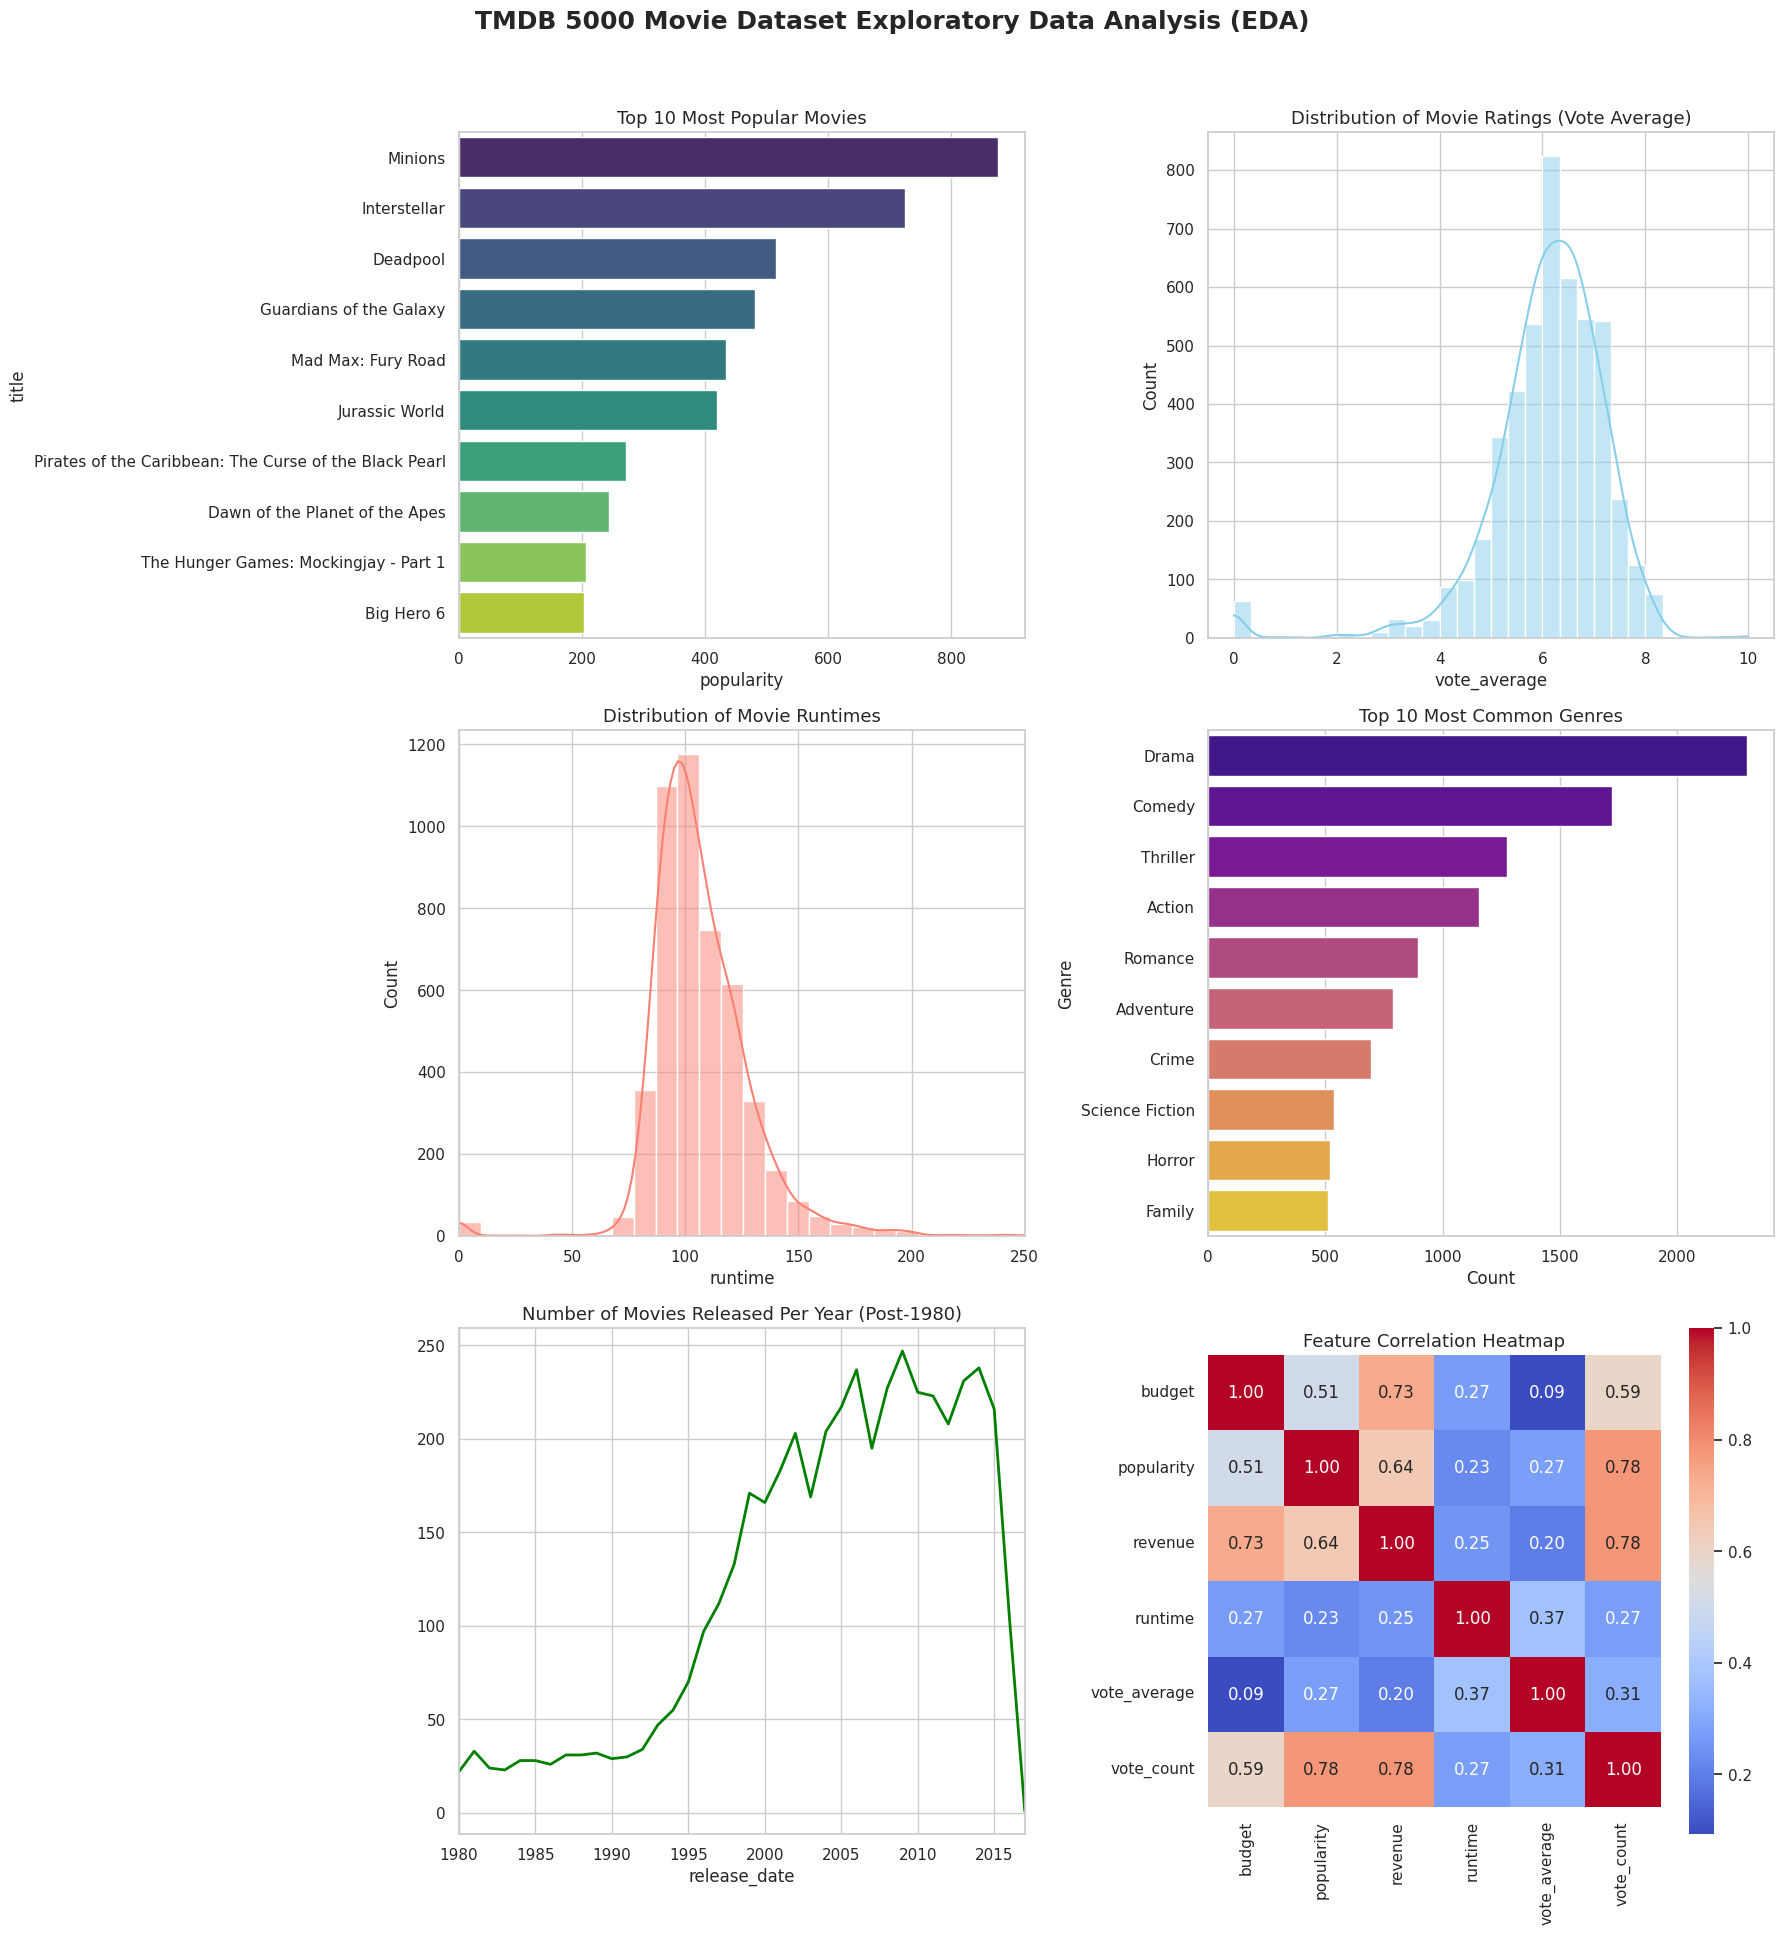

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(18, 20))
fig.suptitle("TMDB 5000 Movie Dataset Exploratory Data Analysis (EDA)", fontsize=18, fontweight='bold')

# 1. Top 10 Most Popular Movies
top_pop = recommendation_data.nlargest(10, 'popularity')
sns.barplot(x='popularity', y='title', data=top_pop, ax=axes[0, 0], palette='viridis', hue='title', legend=False)
axes[0, 0].set_title("Top 10 Most Popular Movies", fontsize=13)

# 2. Distribution of Movie Ratings
sns.histplot(recommendation_data['vote_average'], bins=30, kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title("Distribution of Movie Ratings (Vote Average)", fontsize=13)

# 3. Distribution of Movie Runtimes
sns.histplot(merged_movies['runtime'], bins=35, kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_xlim(0, 250)
axes[1, 0].set_title("Distribution of Movie Runtimes", fontsize=13)

# 4. Top 10 Most Common Genres
all_genres = [g for sublist in recommendation_data['genres'] for g in sublist]
genre_counts = Counter(all_genres)
top_genres_df = pd.DataFrame(genre_counts.most_common(10), columns=['Genre', 'Count'])
sns.barplot(x='Count', y='Genre', data=top_genres_df, ax=axes[1, 1], palette='plasma', hue='Genre', legend=False)
axes[1, 1].set_title("Top 10 Most Common Genres", fontsize=13)

# 5. Movies Released Per Year
years = pd.to_datetime(merged_movies['release_date']).dt.year.dropna().astype(int)
year_counts = years.value_counts().sort_index()
sns.lineplot(x=year_counts.index, y=year_counts.values, ax=axes[2, 0], color='green', linewidth=2)
axes[2, 0].set_xlim(1980, 2017) # Limit to peak years
axes[2, 0].set_title("Number of Movies Released Per Year (Post-1980)", fontsize=13)

# 6. Correlation Heatmap
numeric_cols = merged_movies[['budget', 'popularity', 'revenue', 'runtime', 'vote_average', 'vote_count']]
corr_matrix = numeric_cols.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[2, 1], square=True)
axes[2, 1].set_title("Feature Correlation Heatmap", fontsize=13)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
years = pd.to_datetime(
    merged_movies['release_date'], errors='coerce'
).dt.year.dropna().astype(int)

year_counts = years.value_counts().sort_index()

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    ax=axes[2, 0],
    color='green',
    linewidth=2
)
axes[2, 0].set_title("Movies Released Per Year")
axes[2, 0].set_xlabel("Release Year")
axes[2, 0].set_ylabel("Number of Movies")

Text(411.25, 0.5, 'Number of Movies')

## PHASE 6: Content-Based Recommendation Engine
To scale cleanly across our 4,803 rows without building massive full-size similarity matrices, we vectorize the text using `TfidfVectorizer` and design a memory-efficient matching function that computes cosine similarity on demand for a single target movie against our vectorized sparse matrix.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Initialize and fit TF-IDF vectorizer on the combined features
tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
tfidf_matrix = tfidf.fit_transform(recommendation_data['combined_features'])
print(f"TF-IDF Matrix shape: {tfidf_matrix.shape}")

def recommend_movies_content(movie_title, top_n=10):
    """Content-based movie recommendation using on-demand single-vector Cosine Similarity."""
    # Case-insensitive title matching
    matches = recommendation_data[recommendation_data['title'].str.lower() == movie_title.lower()]

    if matches.empty:
        return f"Movie title '{movie_title}' was not found in the dataset."

    # Handle duplicate movie titles gracefully (grab the first match)
    target_idx = matches.index[0]

    # Extract TF-IDF vector of target movie
    target_vector = tfidf_matrix[target_idx]

    # Compute cosine similarity of target vector against the full TF-IDF matrix
    sim_scores = cosine_similarity(target_vector, tfidf_matrix).flatten()

    # Fetch similarity rankings
    similar_indices = sim_scores.argsort()[::-1]

    # Filter out target index
    similar_indices = [idx for idx in similar_indices if idx != target_idx]

    recommendations = []
    for idx in similar_indices:
        if len(recommendations) >= top_n:
            break
        row = recommendation_data.iloc[idx]
        recommendations.append({
            'Title': row['title'],
            'SimilarityScore': round(float(sim_scores[idx]), 4),
            'Genres': ", ".join(row['genres']),
            'Rating': row['vote_average'],
            'Popularity': round(row['popularity'], 2)
        })

    return pd.DataFrame(recommendations)

TF-IDF Matrix shape: (4803, 10000)


In [ ]:
# Test 1: Avatar
print("===== RECOMMENDATIONS FOR AVATAR =====")
display(recommend_movies_content("Avatar", 10))

# Test 2: The Dark Knight Rises
print("\n===== RECOMMENDATIONS FOR THE DARK KNIGHT RISES =====")
display(recommend_movies_content("The Dark Knight Rises", 10))

# Test 3: Titanic
print("\n===== RECOMMENDATIONS FOR TITANIC =====")
display(recommend_movies_content("Titanic", 10))

# Test 4: Toy Story
print("\n===== RECOMMENDATIONS FOR TOY STORY =====")
display(recommend_movies_content("Toy Story", 10))

# Test 5: The Avengers
print("\n===== RECOMMENDATIONS FOR THE AVENGERS =====")
display(recommend_movies_content("The Avengers", 10))

# Test 6: Invalid movie title
print("\n===== INVALID TITLE TEST =====")
print(recommend_movies_content("Random Unknown Movie"))

===== RECOMMENDATIONS FOR AVATAR =====


,Title,SimilarityScore,Genres,Rating,Popularity
0,Aliens,0.3402,"Horror, Action, Thriller, Science Fiction",7.7,67.66
1,Alien³,0.2824,"Science Fiction, Action, Horror",6.2,45.86
2,Moonraker,0.2766,"Action, Adventure, Thriller, Science Fiction",5.9,29.89
3,Alien,0.2618,"Horror, Action, Thriller, Science Fiction",7.9,94.18
4,Silent Running,0.2505,"Adventure, Drama, Science Fiction",6.3,11.10
5,Lockout,0.2419,"Action, Thriller, Science Fiction",5.8,35.23
6,Mission to Mars,0.2367,Science Fiction,5.7,16.06
7,Spaceballs,0.2346,"Comedy, Science Fiction",6.7,39.89
8,Treasure Planet,0.2236,"Adventure, Animation, Family, Fantasy, Science...",7.2,38.92
9,Lost in Space,0.2233,"Adventure, Family, Science Fiction",5.0,17.46



===== RECOMMENDATIONS FOR THE DARK KNIGHT RISES =====


,Title,SimilarityScore,Genres,Rating,Popularity
0,The Dark Knight,0.4741,"Drama, Action, Crime, Thriller",8.2,187.32
1,Batman Returns,0.3937,"Action, Fantasy",6.6,59.11
2,Batman Begins,0.3809,"Action, Crime, Drama",7.5,115.04
3,Batman,0.3535,"Fantasy, Action",7.0,44.10
4,Batman Forever,0.3496,"Action, Crime, Fantasy",5.2,48.21
5,Batman & Robin,0.2441,"Action, Crime, Fantasy",4.2,50.07
6,Batman v Superman: Dawn of Justice,0.2042,"Action, Adventure, Fantasy",5.7,155.79
7,"Batman: The Dark Knight Returns, Part 2",0.1896,"Action, Animation",7.9,25.89
8,Defendor,0.1457,"Drama, Action, Comedy, Crime",6.5,8.45
9,Slow Burn,0.1220,"Mystery, Crime, Drama, Thriller",5.5,6.63



===== RECOMMENDATIONS FOR TITANIC =====


,Title,SimilarityScore,Genres,Rating,Popularity
0,Raise the Titanic,0.1683,"Action, Drama, Thriller",5.2,1.63
1,Captain Phillips,0.1678,"Action, Drama, Thriller",7.6,52.79
2,Romance & Cigarettes,0.1608,"Comedy, Music, Romance",6.0,4.06
3,Poseidon,0.1586,"Adventure, Action, Drama, Thriller",5.5,21.13
4,Triangle,0.1529,Horror,6.9,25.50
5,Ghost Ship,0.1462,"Horror, Mystery, Thriller",5.3,27.72
6,In the Heart of the Sea,0.1341,"Thriller, Drama, Adventure, Action, History",6.5,50.77
7,The Chambermaid on the Titanic,0.1278,Drama,5.3,1.03
8,Life of Pi,0.1259,"Adventure, Drama, Action",7.2,51.33
9,The Notebook,0.1207,"Romance, Drama",7.7,55.11



===== RECOMMENDATIONS FOR TOY STORY =====


,Title,SimilarityScore,Genres,Rating,Popularity
0,Toy Story 2,0.4519,"Animation, Comedy, Family",7.3,73.58
1,Toy Story 3,0.4340,"Animation, Family, Comedy",7.6,60.00
2,Small Soldiers,0.2597,"Comedy, Adventure, Fantasy, Science Fiction, A...",6.2,23.09
3,The 40 Year Old Virgin,0.1754,"Comedy, Romance",6.2,38.47
4,Child's Play,0.1671,"Horror, Thriller",6.3,27.60
5,In the Shadow of the Moon,0.1609,Documentary,7.6,3.43
6,Child's Play 2,0.1577,"Drama, Horror",5.8,16.68
7,The Indian in the Cupboard,0.1557,"Adventure, Family, Fantasy",5.9,11.10
8,Everything You Always Wanted to Know About Sex...,0.1481,Comedy,6.6,13.22
9,Bananas,0.1462,Comedy,6.7,5.94



===== RECOMMENDATIONS FOR THE AVENGERS =====


,Title,SimilarityScore,Genres,Rating,Popularity
0,Avengers: Age of Ultron,0.5456,"Action, Adventure, Science Fiction",7.3,134.28
1,Captain America: Civil War,0.3676,"Adventure, Action, Science Fiction",7.1,198.37
2,Iron Man 2,0.3246,"Adventure, Action, Science Fiction",6.6,77.30
3,Captain America: The Winter Soldier,0.3070,"Action, Adventure, Science Fiction",7.6,72.23
4,Thor: The Dark World,0.2747,"Action, Adventure, Fantasy",6.8,99.50
5,Iron Man 3,0.2727,"Action, Adventure, Science Fiction",6.8,77.68
6,Iron Man,0.2701,"Action, Science Fiction, Adventure",7.4,120.73
7,Ant-Man,0.2666,"Science Fiction, Action, Adventure",7.0,120.09
8,Fantastic Four,0.2643,"Action, Adventure, Science Fiction",4.4,38.13
9,Captain America: The First Avenger,0.2641,"Action, Adventure, Science Fiction",6.6,74.51



===== INVALID TITLE TEST =====
Movie title 'Random Unknown Movie' was not found in the dataset.


## PHASE 7: Test Recommendations
We test the recommendation engine on 5 popular movies spanning different genres and output the results.

In [ ]:
test_movies = ["Avatar", "The Dark Knight Rises", "Spectre", "Interstellar", "The Avengers"]

for movie in test_movies:
    print(f"\n========== RECOMMENDATIONS FOR '{movie}' ==========")
    res = recommend_movies_content(movie, top_n=5)
    if isinstance(res, pd.DataFrame):
        display(res)
    else:
        print(res)


========== RECOMMENDATIONS FOR 'Avatar' ==========


,Title,SimilarityScore,Genres,Rating,Popularity
0,Aliens,0.3402,"Horror, Action, Thriller, Science Fiction",7.7,67.66
1,Alien³,0.2824,"Science Fiction, Action, Horror",6.2,45.86
2,Moonraker,0.2766,"Action, Adventure, Thriller, Science Fiction",5.9,29.89
3,Alien,0.2618,"Horror, Action, Thriller, Science Fiction",7.9,94.18
4,Silent Running,0.2505,"Adventure, Drama, Science Fiction",6.3,11.10



========== RECOMMENDATIONS FOR 'The Dark Knight Rises' ==========


,Title,SimilarityScore,Genres,Rating,Popularity
0,The Dark Knight,0.4741,"Drama, Action, Crime, Thriller",8.2,187.32
1,Batman Returns,0.3937,"Action, Fantasy",6.6,59.11
2,Batman Begins,0.3809,"Action, Crime, Drama",7.5,115.04
3,Batman,0.3535,"Fantasy, Action",7.0,44.10
4,Batman Forever,0.3496,"Action, Crime, Fantasy",5.2,48.21



========== RECOMMENDATIONS FOR 'Spectre' ==========


,Title,SimilarityScore,Genres,Rating,Popularity
0,Skyfall,0.3225,"Action, Adventure, Thriller",6.9,93.00
1,Never Say Never Again,0.2848,"Adventure, Action, Thriller",5.8,23.38
2,Quantum of Solace,0.2693,"Adventure, Action, Thriller, Crime",6.1,107.93
3,Thunderball,0.2401,"Adventure, Action, Thriller",6.5,31.04
4,From Russia with Love,0.2392,"Action, Thriller, Adventure",6.9,41.30



========== RECOMMENDATIONS FOR 'Interstellar' ==========


,Title,SimilarityScore,Genres,Rating,Popularity
0,Armageddon,0.2333,"Action, Thriller, Science Fiction, Adventure",6.4,58.49
1,Moonraker,0.2311,"Action, Adventure, Thriller, Science Fiction",5.9,29.89
2,Silent Running,0.2233,"Adventure, Drama, Science Fiction",6.3,11.10
3,Cargo,0.2186,"Thriller, Mystery, Science Fiction",5.9,10.14
4,2001: A Space Odyssey,0.2107,"Science Fiction, Mystery, Adventure",7.9,86.20



========== RECOMMENDATIONS FOR 'The Avengers' ==========


,Title,SimilarityScore,Genres,Rating,Popularity
0,Avengers: Age of Ultron,0.5456,"Action, Adventure, Science Fiction",7.3,134.28
1,Captain America: Civil War,0.3676,"Adventure, Action, Science Fiction",7.1,198.37
2,Iron Man 2,0.3246,"Adventure, Action, Science Fiction",6.6,77.30
3,Captain America: The Winter Soldier,0.3070,"Action, Adventure, Science Fiction",7.6,72.23
4,Thor: The Dark World,0.2747,"Action, Adventure, Fantasy",6.8,99.50


## PHASE 8: Recommendation Evaluation
Evaluating a content-based recommendation system is inherently subjective without real historical user rating datasets. We write a function to calculate quality indicators including:
1. **Average similarity score** of recommended movies.
2. **Average genre overlap** (Jaccard similarity) between the target movie and its recommendations.

In [ ]:
def evaluate_recommendations(movie_title, top_n=10):
    matches = recommendation_data[recommendation_data['title'].str.lower() == movie_title.lower()]
    if matches.empty:
        return "Target movie not found."

    target_row = matches.iloc[0]
    target_genres = set(target_row['genres'])

    recs_df = recommend_movies_content(movie_title, top_n=top_n)
    if isinstance(recs_df, str):
        return recs_df

    genre_overlaps = []
    for idx, row in recs_df.iterrows():
        rec_genres = set(row['Genres'].split(", "))
        intersection = target_genres.intersection(rec_genres)
        union = target_genres.union(rec_genres)
        jaccard = len(intersection) / len(union) if len(union) > 0 else 0.0
        genre_overlaps.append(jaccard)

    eval_summary = {
        'Target Movie': target_row['title'],
        'Average Similarity Score': recs_df['SimilarityScore'].mean(),
        'Average Genre Jaccard Overlap': np.mean(genre_overlaps),
        'Recs Genres Represented': list(set([g for r in recs_df['Genres'] for g in r.split(", ")]))
    }
    return eval_summary

# Evaluate recommendations on a key sample
eval_res = evaluate_recommendations("The Dark Knight Rises", top_n=5)
for key, val in eval_res.items():
    print(f"{key}: {val}")

Target Movie: The Dark Knight Rises
Average Similarity Score: 0.39036
Average Genre Jaccard Overlap: 0.51
Recs Genres Represented: ['Crime', 'Action', 'Drama', 'Thriller', 'Fantasy']


In [ ]:
evaluation_movies = [
    "Avatar",
    "The Dark Knight Rises",
    "Spectre",
    "Interstellar",
    "The Avengers"
]

evaluation_results = []

for movie in evaluation_movies:
    result = evaluate_recommendations(movie, top_n=5)

    if isinstance(result, dict):
        evaluation_results.append({
            "Movie": result["Target Movie"],
            "Average Similarity": result["Average Similarity Score"],
            "Average Genre Overlap": result["Average Genre Jaccard Overlap"],
            "Unique Genres": len(result["Recs Genres Represented"])
        })

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)

,Movie,Average Similarity,Average Genre Overlap,Unique Genres
0,Avatar,0.28230,0.413333,6
1,The Dark Knight Rises,0.39036,0.510000,5
2,Spectre,0.27118,0.550000,4
3,Interstellar,0.22340,0.500000,6
4,The Avengers,0.36390,0.900000,4


## PHASE 9: Popularity-Based Recommendation
We formulate a weighted ranking using **IMDb's Weighted Rating formula**:
$$WR = \left(\frac{v}{v+m}\right) R + \left(\frac{m}{v+m}\right) C$$
where:
* $v$ is the number of votes for the movie (`vote_count`)
* $m$ is the minimum votes required to be listed in the chart (we use 90th percentile)
* $R$ is the average rating of the movie (`vote_average`)
* $C$ is the mean vote across the whole dataset

In [ ]:
C = recommendation_data['vote_average'].mean()
m = recommendation_data['vote_count'].quantile(0.90)

print(f"Mean Rating (C): {C:.3f}")
print(f"Min votes threshold (m): {m:.1f}")

def calculate_weighted_rating(x, m=m, C=C):
    v = x['vote_count']
    R = x['vote_average']
    return (v/(v+m) * R) + (m/(v+m) * C)

# Filter eligible movies and calculate scores
qualified_movies = recommendation_data[recommendation_data['vote_count'] >= m].copy()
qualified_movies['weighted_score'] = qualified_movies.apply(calculate_weighted_rating, axis=1)
qualified_movies = qualified_movies.sort_values('weighted_score', ascending=False)

def recommend_popular_movies(top_n=10):
    output_df = qualified_movies.head(top_n)[['title', 'genres', 'vote_average', 'vote_count', 'weighted_score']]
    output_df['genres'] = output_df['genres'].apply(lambda x: ", ".join(x))
    return output_df

print("\n=== TOP 10 POPULAR MOVIES USING IMDB WEIGHTED RATING ===")
display(recommend_popular_movies(10))

Mean Rating (C): 6.092
Min votes threshold (m): 1838.4

=== TOP 10 POPULAR MOVIES USING IMDB WEIGHTED RATING ===


,title,genres,vote_average,vote_count,weighted_score
1881,The Shawshank Redemption,"Drama, Crime",8.5,8205,8.059258
662,Fight Club,Drama,8.3,9413,7.939256
65,The Dark Knight,"Drama, Action, Crime, Thriller",8.2,12002,7.920020
3232,Pulp Fiction,"Thriller, Crime",8.3,8428,7.904645
96,Inception,"Action, Thriller, Science Fiction, Mystery, Ad...",8.1,13752,7.863239
3337,The Godfather,"Drama, Crime",8.4,5893,7.851236
95,Interstellar,"Adventure, Drama, Science Fiction",8.1,10867,7.809479
809,Forrest Gump,"Comedy, Drama, Romance",8.2,7927,7.803188
329,The Lord of the Rings: The Return of the King,"Adventure, Fantasy, Action",8.1,8064,7.727243
1990,The Empire Strikes Back,"Adventure, Action, Science Fiction",8.2,5879,7.697884


## PHASE 10: Hybrid Recommendation System
We build a hybrid recommendation system that combines content-based similarity scores and popularity ratings to ensure a balanced, high-quality prediction list.

In [ ]:
def recommend_hybrid(movie_title, top_n=10, content_weight=0.6, popularity_weight=0.4):
    """Combines on-demand content similarity with IMDb weighted popularity score."""
    matches = recommendation_data[recommendation_data['title'].str.lower() == movie_title.lower()]
    if matches.empty:
        return f"Movie '{movie_title}' not found."

    target_idx = matches.index[0]
    target_vector = tfidf_matrix[target_idx]

    # 1. Content similarities
    sim_scores = cosine_similarity(target_vector, tfidf_matrix).flatten()

    # 2. Build scoring DataFrame
    scores_df = recommendation_data.copy()
    scores_df['similarity_score'] = sim_scores

    # Apply IMDB Weighted Rating score
    scores_df['popularity_score'] = scores_df.apply(lambda x: calculate_weighted_rating(x), axis=1)

    # Scale popularity score to a [0, 1] range for unified combination
    min_pop = scores_df['popularity_score'].min()
    max_pop = scores_df['popularity_score'].max()
    scores_df['normalized_popularity'] = (scores_df['popularity_score'] - min_pop) / (max_pop - min_pop)

    # Calculate unified hybrid score
    scores_df['hybrid_score'] = (
        content_weight * scores_df['similarity_score'] +
        popularity_weight * scores_df['normalized_popularity']
    )

    # Sort & filter target movie
    scores_df = scores_df[scores_df.index != target_idx]
    scores_df = scores_df.sort_values('hybrid_score', ascending=False)

    output_list = []
    for idx, row in scores_df.head(top_n).iterrows():
        output_list.append({
            'Title': row['title'],
            'Genres': ", ".join(row['genres']),
            'SimilarityScore': round(float(row['similarity_score']), 4),
            'PopularityScore': round(float(row['normalized_popularity']), 4),
            'HybridScore': round(float(row['hybrid_score']), 4)
        })

    return pd.DataFrame(output_list)

print("=== HYBRID RECOMMENDATIONS FOR 'The Avengers' ===")
display(recommend_hybrid('The Avengers', top_n=5))

=== HYBRID RECOMMENDATIONS FOR 'The Avengers' ===


,Title,Genres,SimilarityScore,PopularityScore,HybridScore
0,Avengers: Age of Ultron,"Action, Adventure, Science Fiction",0.5456,0.6496,0.5872
1,Guardians of the Galaxy,"Action, Science Fiction, Adventure",0.2295,0.8463,0.4762
2,Captain America: The Winter Soldier,"Action, Adventure, Science Fiction",0.3070,0.7162,0.4707
3,Captain America: Civil War,"Adventure, Action, Science Fiction",0.3676,0.5993,0.4603
4,Iron Man,"Action, Science Fiction, Adventure",0.2701,0.6949,0.4400


In [ ]:
test_movies = [
    "The Avengers",
    "The Dark Knight Rises",
    "Interstellar"
]

for movie in test_movies:
    print(f"\n{'='*60}")
    print(f"HYBRID RECOMMENDATIONS FOR: {movie}")
    print('='*60)

    display(recommend_hybrid(movie, top_n=5))


HYBRID RECOMMENDATIONS FOR: The Avengers


,Title,Genres,SimilarityScore,PopularityScore,HybridScore
0,Avengers: Age of Ultron,"Action, Adventure, Science Fiction",0.5456,0.6496,0.5872
1,Guardians of the Galaxy,"Action, Science Fiction, Adventure",0.2295,0.8463,0.4762
2,Captain America: The Winter Soldier,"Action, Adventure, Science Fiction",0.3070,0.7162,0.4707
3,Captain America: Civil War,"Adventure, Action, Science Fiction",0.3676,0.5993,0.4603
4,Iron Man,"Action, Science Fiction, Adventure",0.2701,0.6949,0.4400



HYBRID RECOMMENDATIONS FOR: The Dark Knight Rises


,Title,Genres,SimilarityScore,PopularityScore,HybridScore
0,The Dark Knight,"Drama, Action, Crime, Thriller",0.4741,0.9520,0.6653
1,Batman Begins,"Action, Crime, Drama",0.3809,0.7105,0.5127
2,Inception,"Action, Thriller, Science Fiction, Mystery, Ad...",0.0654,0.9325,0.4123
3,Interstellar,"Adventure, Drama, Science Fiction",0.0731,0.9140,0.4094
4,The Shawshank Redemption,"Drama, Crime",0.0149,1.0000,0.4089



HYBRID RECOMMENDATIONS FOR: Interstellar


,Title,Genres,SimilarityScore,PopularityScore,HybridScore
0,The Empire Strikes Back,"Adventure, Action, Science Fiction",0.1071,0.8755,0.4145
1,Guardians of the Galaxy,"Action, Science Fiction, Adventure",0.1207,0.8463,0.4109
2,2001: A Space Odyssey,"Science Fiction, Mystery, Adventure",0.2107,0.7085,0.4098
3,The Dark Knight,"Drama, Action, Crime, Thriller",0.0473,0.9520,0.4092
4,The Martian,"Drama, Adventure, Science Fiction",0.1838,0.7370,0.4051


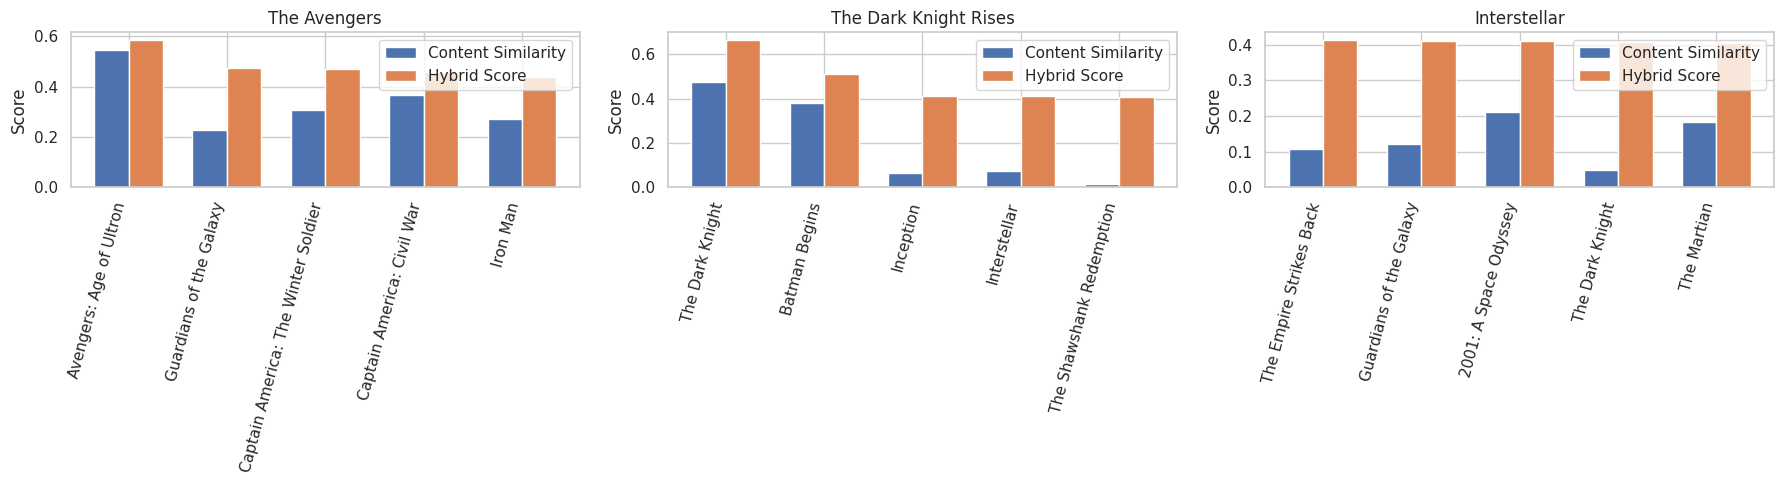

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

test_movies = [
    "The Avengers",
    "The Dark Knight Rises",
    "Interstellar"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, movie in enumerate(test_movies):

    content_df = recommend_movies_content(movie, top_n=5)
    hybrid_df = recommend_hybrid(movie, top_n=5)

    if isinstance(content_df, str) or isinstance(hybrid_df, str):
        continue

    comparison = pd.DataFrame({
        'Movie': hybrid_df['Title'],
        'Content Similarity': hybrid_df['SimilarityScore'],
        'Hybrid Score': hybrid_df['HybridScore']
    })

    x = np.arange(len(comparison))
    width = 0.35

    axes[i].bar(
        x - width/2,
        comparison['Content Similarity'],
        width,
        label='Content Similarity'
    )

    axes[i].bar(
        x + width/2,
        comparison['Hybrid Score'],
        width,
        label='Hybrid Score'
    )

    axes[i].set_title(movie)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(
        comparison['Movie'],
        rotation=75,
        ha='right'
    )
    axes[i].set_ylabel('Score')
    axes[i].legend()

plt.tight_layout()
plt.show()

## PHASE 11: Collaborative Filtering Explanation
Since the TMDB 5000 dataset only contains item metadata, we cannot execute standard collaborative filtering (which requires user interactions like explicit ratings or reviews). Here is an architectural diagram block illustrating how a ratings dataset (e.g. MovieLens) would be linked to implement user-based collaborative filtering via matrix factorization.

In [ ]:
print("=== COLLABORATIVE FILTERING EXPLANATION ===")
print("""
The TMDB 5000 dataset lacks transactional user-movie rating maps (e.g., UserId, MovieId, Rating).
To build a collaborative filtering component, we would typically:
1. Integrate external datasets like MovieLens (ml-latest-small).
2. Construct a user-item matrix where entry (u, i) holds rating r_ui.
3. Apply Collaborative Filtering Algorithms (such as SVD Matrix Factorization, or item-based neighborhood systems).
""")

=== COLLABORATIVE FILTERING EXPLANATION ===

The TMDB 5000 dataset lacks transactional user-movie rating maps (e.g., UserId, MovieId, Rating).
To build a collaborative filtering component, we would typically:
1. Integrate external datasets like MovieLens (ml-latest-small).
2. Construct a user-item matrix where entry (u, i) holds rating r_ui.
3. Apply Collaborative Filtering Algorithms (such as SVD Matrix Factorization, or item-based neighborhood systems).



## PHASE 12: Recommendation Visualization
We visualize comparisons of content-based vs hybrid recommendations.

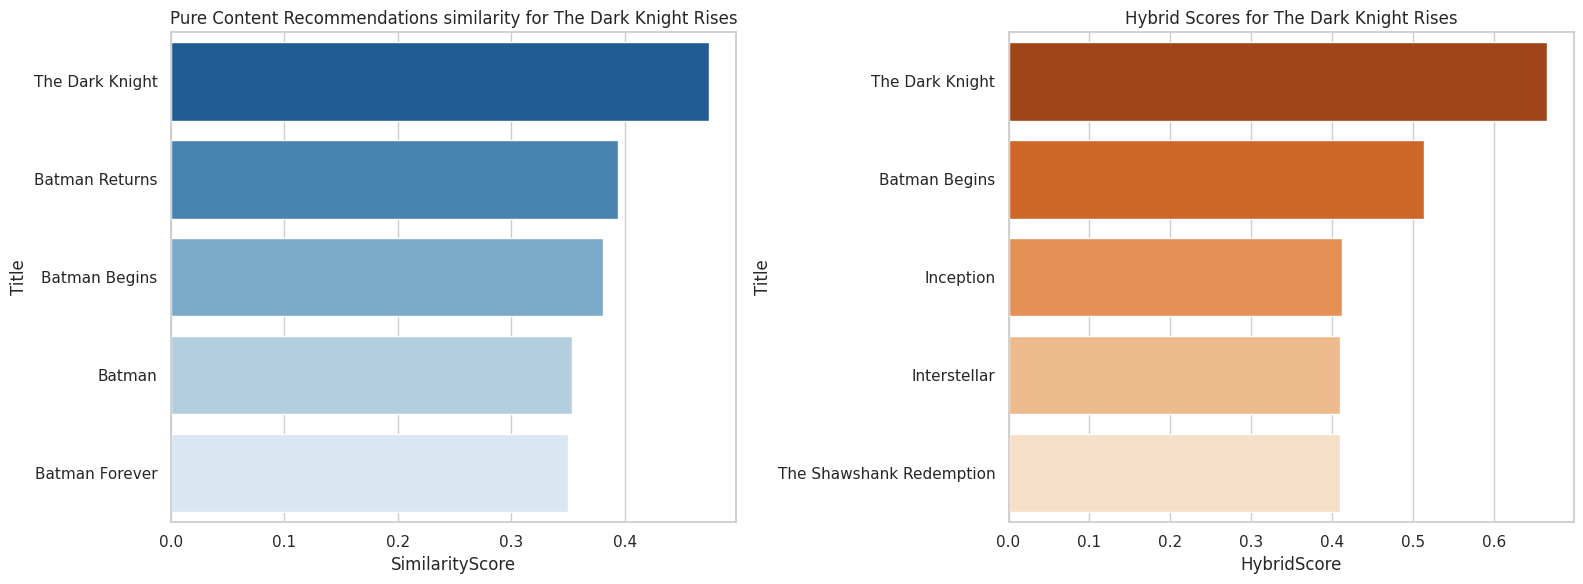

In [ ]:
target_movie = "The Dark Knight Rises"
content_recs = recommend_movies_content(target_movie, top_n=5)
hybrid_recs = recommend_hybrid(target_movie, top_n=5)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='SimilarityScore', y='Title', data=content_recs, ax=axes[0], palette='Blues_r', hue='Title', legend=False)
axes[0].set_title(f"Pure Content Recommendations similarity for {target_movie}")

sns.barplot(x='HybridScore', y='Title', data=hybrid_recs, ax=axes[1], palette='Oranges_r', hue='Title', legend=False)
axes[1].set_title(f"Hybrid Scores for {target_movie}")

plt.tight_layout()
plt.show()

## PHASE 13: Interactive Movie Recommendation Interface
We build an attractive interactive UI using `Gradio`. If Gradio is not installed, the code automatically handles installing it dynamically so everything runs seamlessly.

In [ ]:
import sys
try:
    import gradio as gr
except ImportError:
    !pip install -q gradio
    import gradio as gr

def run_gradio_recommender(movie_title, method, num_recs):
    if not movie_title:
        return "Please enter a valid movie title."

    num_recs = int(num_recs)

    if method == "Content-Based":
        res = recommend_movies_content(movie_title, top_n=num_recs)
    elif method == "Popularity-Based":
        res = recommend_popular_movies(top_n=num_recs)
    elif method == "Hybrid":
        res = recommend_hybrid(movie_title, top_n=num_recs)
    else:
        return "Invalid Method"

    if isinstance(res, str):
        return res
    return res.to_html(index=False, classes='table table-striped table-hover')

# Configure and launch the UI block
interface = gr.Interface(
    fn=run_gradio_recommender,
    inputs=[
        gr.Textbox(label="Enter Movie Title (e.g. 'Avatar', 'Spectre')", value="Avatar"),
        gr.Dropdown(choices=["Content-Based", "Popularity-Based", "Hybrid"], label="Recommendation Mode", value="Hybrid"),
        gr.Slider(minimum=1, maximum=20, step=1, value=10, label="Count")
    ],
    outputs=gr.HTML(label="Recommendations Table"),
    title="🎬 AI/ML Movie Recommendation System",
    description="Select a movie and dynamic mode (Pure Content Similarity, IMDB Weighted Rating Popularity, or Hybrid Scoring) to see real-time suggestions.",
    theme="soft"
)

# Launch inside Colab smoothly
interface.launch(share=True, debug=False)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ec906eaaec7162d21c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## PHASE 14: Save Project Files & Model Artifacts
We dump the processed recommendation metadata database along with the fitted TF-IDF matrix model weights and download them.

In [ ]:
import pickle
from google.colab import files

# 1. Save Datasets to CSV
recommendation_data.to_csv('recommendation_data.csv', index=False)
print("Saved recommendation_data.csv successfully.")

# 2. Save Fitted TF-IDF Model Artifact
with open('tfidf_model.pkl', 'wb') as f:
    pickle.dump((tfidf, tfidf_matrix), f)
print("Saved tfidf_model.pkl successfully.")

# Trigger browser downloads
files.download('recommendation_data.csv')
files.download('tfidf_model.pkl')

Saved recommendation_data.csv successfully.
Saved tfidf_model.pkl successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## PHASE 15: Professional GitHub README.md
This Markdown content serves as a complete project document and setup manual.

# 🎬 TMDB Movie Recommendation System

This repository provides a complete End-to-End AI/ML Movie Recommendation System built on top of the classic **TMDB 5000 Movie Dataset**.

## 🛠️ Technologies Used
* **Python 3.10+**
* **Pandas / NumPy** (Data wrangling & matrices)
* **Scikit-Learn** (TF-IDF vectorizer & cosine distance maps)
* **Matplotlib / Seaborn** (Data exploration)
* **Gradio** (Modern Web UI interface)

## 🚀 Project Steps
1. **Data Integration**: Joined raw metadata features safely.
2. **Feature Extraction**: Evaluated nested JSON items safely using `ast.literal_eval` to fetch cast, keywords, genres, and directors.
3. **Metadata Combination**: Created a metadata-soup feature vector `combined_features`.
4. **Scalable Cosine-Similarity Engine**: Implemented an on-demand, memory-efficient algorithm to dynamically compute similarity arrays.
5. **IMDb Weighted Scoring Formula**: Implemented a popularity-based engine to suggest high-performing global favorites.
6. **Hybrid System**: Unified text features and weighted performance indices smoothly.

# 🎬 TMDB Movie Recommendation System

This repository provides a complete End-to-End AI/ML Movie Recommendation System built on top of the classic **TMDB 5000 Movie Dataset**.

## 🛠️ Technologies Used
* **Python 3.10+**
* **Pandas / NumPy** (Data wrangling & matrices)
* **Scikit-Learn** (TF-IDF vectorizer & cosine distance maps)
* **Matplotlib / Seaborn** (Data exploration)
* **Gradio** (Modern Web UI interface)

## 🚀 Project Steps
1. **Data Integration**: Joined raw metadata features safely.
2. **Feature Extraction**: Evaluated nested JSON items safely using `ast.literal_eval` to fetch cast, keywords, genres, and directors.
3. **Metadata Combination**: Created a metadata-soup feature vector `combined_features`.
4. **Scalable Cosine-Similarity Engine**: Implemented an on-demand, memory-efficient algorithm to dynamically compute similarity arrays.
5. **IMDb Weighted Scoring Formula**: Implemented a popularity-based engine to suggest high-performing global favorites.
6. **Hybrid System**: Unified text features and weighted performance indices smoothly.

## 📊 7. Dataset Description
This project utilizes the **TMDB 5000 Movie Dataset**, which consists of two interconnected tables:
* **tmdb_5000_movies.csv**: Contains metadata for 4,803 films (including columns such as budget, genres, homepage, id, keywords, original_language, original_title, overview, popularity, release_date, revenue, runtime, vote_average, and vote_count).
* **tmdb_5000_credits.csv**: Contains details on film talent, specifically the structured string records for `cast` and `crew` lists linked by `movie_id`.

## 🔑 8. Key Features
* **Robust JSON Handling**: Custom parsers safely handle stringified nested data fields using `ast.literal_eval`.
* **Metadata Cleaning**: Extracted and normalized genres, keywords, cast, director, overview and language while preserving spaces between words.
* **Content-Based Recommendations**: Uses TF-IDF and cosine similarity to find movies with similar metadata.
* **IMDb-Style Weighted Rating**: Balances movie ratings with vote counts to reduce the influence of movies with very few votes.
* **Hybrid Recommendations**: Combines 60% content similarity and 40% normalized weighted popularity.
* **Interactive Interface**: Gradio-based interface for selecting movies and recommendation modes.

## 🧮 9. Recommendation Algorithms

### A. Content-Based Filtering
Movie metadata is transformed into numerical vectors using Term Frequency-Inverse Document Frequency (TF-IDF), with a maximum of 10,000 features. Cosine similarity measures the similarity between two movie vectors:
$$\text{Cosine Similarity}(A,B)=\frac{A\cdot B}{\|A\|\|B\|}$$
The system calculates similarities on demand instead of storing a complete movie-to-movie similarity matrix.

### B. IMDb-Style Weighted Rating
The system uses the weighted rating formula:
$$WR=\frac{v}{v+m}R+\frac{m}{v+m}C$$
Where:
* **$v$**: Number of votes for a movie (`vote_count`)
* **$m$**: Minimum vote threshold (90th percentile of vote counts, approximately 1838.4)
* **$R$**: Movie's average rating (`vote_average`)
* **$C$**: Mean rating across the dataset (approximately 6.092)

### C. Hybrid Recommendation
The hybrid model combines content similarity and normalized weighted popularity:
$$\text{Hybrid Score}=0.6S+0.4P$$
Where:
* **$S$**: Content similarity score
* **$P$**: Normalized weighted popularity score

## 📈 10. Model Evaluation & Observations
The recommendation system was tested using multiple movies, including Avatar, The Dark Knight Rises, Spectre, Interstellar and The Avengers.
* **Content Similarity**: The Dark Knight Rises returned The Dark Knight with a similarity score of 0.4741.
* **Genre Jaccard Overlap**: The Dark Knight Rises achieved an average genre Jaccard overlap of 0.51 across its top five content-based recommendations.
* **Hybrid Recommendations**: For The Avengers, Avengers: Age of Ultron ranked first with a hybrid score of 0.5872.
* **Popularity Influence**: For Interstellar, The Empire Strikes Back ranked first with a hybrid score of 0.4145.

These are proxy evaluation observations. They do not represent measured user satisfaction or standard precision/recall metrics.

## ⚠️ 11. Limitations
* **No User-Level Ratings**: The TMDB 5000 dataset does not contain individual user-movie rating interactions.
* **Collaborative Filtering**: A genuine collaborative filtering model has not been implemented.
* **Popularity Bias**: The hybrid model may recommend highly rated movies with relatively low content similarity because popularity contributes 40% of the hybrid score.
* **Cold Start**: New movies with limited metadata may receive weaker content-based recommendations.

## 🔮 12. Future Scope
* Integrate MovieLens ratings to implement collaborative filtering using matrix factorization or user/item-based methods.
* Explore transformer-based text embeddings such as Sentence-BERT.
* Improve hybrid score weighting through systematic evaluation.
* Add movie posters, descriptions and additional filtering options to the interface.

## 💻 13. Installation & Google Colab Execution
1. Open the project notebook in Google Colab.
2. Upload or mount the TMDB dataset files.
3. Run notebook cells sequentially, starting with dataset loading and preprocessing.
4. Install the required Python libraries if they are not already available.
5. Run the Gradio interface cell to launch the interactive application.

A standard CPU runtime is sufficient for this project; GPU is optional.

## 📦 14. Saved Artifacts
* **`recommendation_data.csv`**: Processed movie metadata containing extracted features and recommendation-related fields.
* **`tfidf_model.pkl`**: Pickled tuple containing the fitted TF-IDF vectorizer and its transformed sparse matrix.

## 📂 15. Project Folder Structure
```text
TMDB-Movie-Recommendation-System/
├── tmdb_dataset/
│   ├── tmdb_5000_movies.csv
│   └── tmdb_5000_credits.csv
├── recommendation_data.csv
├── tfidf_model.pkl
├── TMDB_Movie_Recommendation_System.ipynb
└── README.md
```

## 🖥️ 16. Gradio Interface Instructions
1. Run the Gradio interface cell in Google Colab.
2. Open the temporary public URL generated in the output.
3. Enter a movie title, such as `Avatar` or `Spectre`.
4. Select a recommendation mode:
   - Pure Content Similarity
   - IMDb Weighted Rating Popularity
   - Hybrid
5. Choose the desired number of recommendations and submit.

The public Gradio share link is temporary and depends on the active runtime.

## 👥 17. Author
* **Your Name**
* GitHub: [Your GitHub Profile](https://github.com/)
* LinkedIn: [Your LinkedIn Profile](https://www.linkedin.com/)

In [40]:
readme_content = r"""
# 🎬 TMDB Movie Recommendation System

This repository provides a complete End-to-End AI/ML Movie Recommendation System built on top of the classic **TMDB 5000 Movie Dataset**.

## 🛠️ Technologies Used
* **Python 3.10+**
* **Pandas / NumPy** (Data wrangling & matrices)
* **Scikit-Learn** (TF-IDF vectorizer & cosine distance maps)
* **Matplotlib / Seaborn** (Data exploration)
* **Gradio** (Modern Web UI interface)

## 🚀 Project Steps
1. **Data Integration**: Joined raw metadata features safely.
2. **Feature Extraction**: Evaluated nested JSON items safely using `ast.literal_eval` to fetch cast, keywords, genres, and directors.
3. **Metadata Combination**: Created a metadata-soup feature vector `combined_features`.
4. **Scalable Cosine-Similarity Engine**: Implemented an on-demand, memory-efficient algorithm to dynamically compute similarity arrays.
5. **IMDb Weighted Scoring Formula**: Implemented a popularity-based engine to suggest high-performing global favorites.
6. **Hybrid System**: Unified text features and weighted performance indices smoothly.

## 📊 Dataset Description
This project utilizes the **TMDB 5000 Movie Dataset**, which consists of two interconnected tables:
* **tmdb_5000_movies.csv**: Contains metadata for 4,803 films (including columns such as budget, genres, homepage, id, keywords, original_language, original_title, overview, popularity, release_date, revenue, runtime, vote_average, and vote_count).
* **tmdb_5000_credits.csv**: Contains details on film talent, specifically the structured string records for `cast` and `crew` lists linked by `movie_id`.

## 🔑 Key Features
* **Robust JSON Handling**: Custom parsers safely handle stringified nested data fields using `ast.literal_eval`.
* **Metadata Cleaning**: Extracted and normalized genres, keywords, cast, director, overview and language while preserving spaces between words.
* **Content-Based Recommendations**: Uses TF-IDF and cosine similarity to find movies with similar metadata.
* **IMDb-Style Weighted Rating**: Balances movie ratings with vote counts to reduce the influence of movies with very few votes.
* **Hybrid Recommendations**: Combines 60% content similarity and 40% normalized weighted popularity.
* **Interactive Interface**: Gradio-based interface for selecting movies and recommendation modes.

## 🧮 Recommendation Algorithms

### A. Content-Based Filtering
Movie metadata is transformed into numerical vectors using Term Frequency-Inverse Document Frequency (TF-IDF), with a maximum of 10,000 features. Cosine similarity measures the similarity between two movie vectors:
$$\text{Cosine Similarity}(A,B)=\frac{A\cdot B}{\|A\|\|B\|}$$
The system calculates similarities on demand instead of storing a complete movie-to-movie similarity matrix.

### B. IMDb-Style Weighted Rating
The system uses the weighted rating formula:
$$WR=\frac{v}{v+m}R+\frac{m}{v+m}C$$
Where:
* **$v$**: Number of votes for a movie (`vote_count`)
* **$m$**: Minimum vote threshold (90th percentile of vote counts, approximately 1838.4)
* **$R$**: Movie's average rating (`vote_average`)
* **$C$**: Mean rating across the dataset (approximately 6.092)

### C. Hybrid Recommendation
The hybrid model combines content similarity and normalized weighted popularity:
$$\text{Hybrid Score}=0.6S+0.4P$$
Where:
* **$S$**: Content similarity score
* **$P$**: Normalized weighted popularity score

## 📈 Model Evaluation & Observations
The recommendation system was tested using multiple movies, including Avatar, The Dark Knight Rises, Spectre, Interstellar and The Avengers.
* **Content Similarity**: The Dark Knight Rises returned The Dark Knight with a similarity score of 0.4741.
* **Genre Jaccard Overlap**: The Dark Knight Rises achieved an average genre Jaccard overlap of 0.51 across its top five content-based recommendations.
* **Hybrid Recommendations**: For The Avengers, Avengers: Age of Ultron ranked first with a hybrid score of 0.5872.
* **Popularity Influence**: For Interstellar, The Empire Strikes Back ranked first with a hybrid score of 0.4145.

These are proxy evaluation observations. They do not represent measured user satisfaction or standard precision/recall metrics.

## ⚠️ Limitations
* **No User-Level Ratings**: The TMDB 5000 dataset does not contain individual user-movie rating interactions.
* **Collaborative Filtering**: A genuine collaborative filtering model has not been implemented.
* **Popularity Bias**: The hybrid model may recommend highly rated movies with relatively low content similarity because popularity contributes 40% of the hybrid score.
* **Cold Start**: New movies with limited metadata may receive weaker content-based recommendations.

## 🔮 Future Scope
* Integrate MovieLens ratings to implement collaborative filtering using matrix factorization or user/item-based methods.
* Explore transformer-based text embeddings such as Sentence-BERT.
* Improve hybrid score weighting through systematic evaluation.
* Add movie posters, descriptions and additional filtering options to the interface.

## 💻 Installation & Google Colab Execution
1. Open the project notebook in Google Colab.
2. Upload or mount the TMDB dataset files.
3. Run notebook cells sequentially, starting with dataset loading and preprocessing.
4. Install the required Python libraries if they are not already available.
5. Run the Gradio interface cell to launch the interactive application.

A standard CPU runtime is sufficient for this project; GPU is optional.

## 📦 Saved Artifacts
* **`recommendation_data.csv`**: Processed movie metadata containing extracted features and recommendation-related fields.
* **`tfidf_model.pkl`**: Pickled tuple containing the fitted TF-IDF vectorizer and its transformed sparse matrix.

## 📂 Project Folder Structure
```text
TMDB-Movie-Recommendation-System/
├── tmdb_dataset/
│   ├── tmdb_5000_movies.csv
│   └── tmdb_5000_credits.csv
├── recommendation_data.csv
├── tfidf_model.pkl
├── TMDB_Movie_Recommendation_System.ipynb
└── README.md
```

## 🖥️ Gradio Interface Instructions
1. Run the Gradio interface cell in Google Colab.
2. Open the temporary public URL generated in the output.
3. Enter a movie title, such as `Avatar` or `Spectre`.
4. Select a recommendation mode:
   - Pure Content Similarity
   - IMDb Weighted Rating Popularity
   - Hybrid
5. Choose the desired number of recommendations and submit.

The public Gradio share link is temporary and depends on the active runtime.
## 👥 17. Author

- **Your Name**
- GitHub: [Your GitHub Profile](https://github.com/your-username)
- LinkedIn: [Your LinkedIn Profile](https://www.linkedin.com/in/your-profile/)
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content.strip() + "\n")

print("README.md created successfully!")

README.md created successfully!


In [41]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>